# Notebook 04 — Clusterização com K-Means: os dados se separam sozinhos?

**O que buscamos aqui:** descobrir o quanto as condições do ventilador (velocidade e falha) se separam **sem que o algoritmo saiba os rótulos**. Se os grupos aparecem sozinhos, a diferença entre as condições é real e forte, e um classificador treinado com rótulos (Notebook 05) tende a funcionar ainda melhor. Se não aparecem, entendemos **por quê** antes de treinar qualquer modelo.

**Os rótulos (velocidade e condição) ficam guardados à parte** e só entram no fim de cada experimento, para conferir o que o K-Means encontrou. A única exceção está explicada no Passo 4 (o scaler local "b").

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configuração | Conjuntos de features, opções de log e scaler |
| 2 | Carregar as bases e calcular as 109 features | A mesma tabela dos Notebooks 02 e 03 |
| 3 | Transformação logarítmica | Reduzir a cauda comprida das features |
| 4 | Padronização (scaler) global e local | Colocar as features na mesma escala sem apagar o que importa |
| 5 | Como medir: matriz de confusão, acurácia, recall, precisão, ARI | Saber ler cada resultado |
| 6 | K=3 só no Normal | O K-Means acha as 3 velocidades? |
| 7 | K=3 só na anomalia | E com a falha? |
| 8 | K=2 global | Separa normal de falha sem saber a velocidade? |
| 9 | K=2 em cada velocidade (scaler local) | O teste principal de detecção |
| 10 | K=6 | Velocidade e condição ao mesmo tempo |
| 11 | Silhueta | Os dados "pedem" quantos grupos, sem olhar rótulos? |
| 12 | Checagens anti-ilusão | Fase do ciclo, deriva, estabilidade, janelas atípicas |
| Resumo | Tabela final e decisões | O que levar para o Notebook 05 |

## O que é o K-Means (em uma linha)

Ele recebe as janelas como pontos num espaço de 109 dimensões (uma por feature), escolhe **K centros** e coloca cada janela no grupo do centro mais próximo, ajustando os centros até estabilizar. **Ele mede distância**, por isso a escala das features (Passos 3 e 4) muda tudo.

## Ressalvas que valem para todo o notebook

* **Só existe um tipo de falha (a fita) e ela é forte.** Separar 100% aqui mostra que a fita é detectável, não que o método pega falhas sutis. A nova coleta responde isso.
* **O ciclo da oscilação** (Notebook 03) faz o mesmo ventilador alternar janelas fortes e fracas. O Passo 12 confere se o K-Means não está separando essa alternância em vez da falha.
* **Não há divisão treino/teste aqui.** O K-Means não aprende rótulos, então não existe "decorar a resposta". Mas os scalers são ajustados nos próprios dados analisados. Isso serve para a **viabilidade**; no Notebook 05 os scalers serão ajustados **só no treino**.

## Como usar

1. Use a mesma pasta de bases dos notebooks anteriores (`<condicao>_vel_<N>.csv`).
2. No Passo 1, confira `CONDICOES_REFERENCIA`. Condições novas entram sozinhas. Com mais de uma falha, os experimentos de "anomalia" juntam todas as falhas, e o K=6 vira K = velocidades × condições.
3. Rode em ordem. **Em cada passo, leia o texto antes do resultado.**

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte. Precisa de `scikit-learn` instalado (os notebooks antigos já usavam).

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. Os blocos "LOG", "SCALER" e "K-MEANS" são explicados nos Passos 3, 4 e 5.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, rankdata
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos notebooks anteriores)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\BASES_ROTULADAS")

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA (NORMAL) E QUEM É ANOMALIA
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta
NOME_NORMAL = "normal"                         # rótulo usado nas matrizes para a referência
NOME_ANOMALIA = "anomalia"                     # rótulo binário das falhas (no K=2)

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6

# ----------------------------------------------------------------------
# LOG (Passo 3)
# ----------------------------------------------------------------------
APLICAR_LOG = True
COLUNAS_SEM_LOG = ["kurt_x", "kurt_y", "kurt_z"]   # a curtose pode ser negativa: não aceita log

# ----------------------------------------------------------------------
# K-MEANS
# ----------------------------------------------------------------------
N_INIT = 20                       # o K-Means recomeça 20 vezes de pontos diferentes e fica com o melhor resultado
SEMENTE = 42                      # fixa os sorteios para o resultado ser sempre igual
CONJUNTO_PRINCIPAL = "todas"      # conjunto de features mostrado nas matrizes (os outros aparecem nas tabelas)
K_SILHUETA = range(2, 9)          # valores de K testados na silhueta (Passo 11)
N_SEMENTES_ESTABILIDADE = 10      # quantas sementes diferentes no teste de estabilidade (Passo 12)

# ----------------------------------------------------------------------
# JANELAS ATÍPICAS (Passo 12, mesmo critério do Notebook 03)
# ----------------------------------------------------------------------
LIMITE_Z_ROBUSTO = 8
MIN_FEATURES_ATIPICAS = 10

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_VELOCIDADE = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
MARCADORES_CONDICAO = ["o", "X", "s", "^", "D", "P"]   # um por condição, na ordem: referência, depois as anomalias

## Passo 2 — Carregar as bases e calcular as 109 features

**O que buscamos:** a mesma tabela dos Notebooks 02 e 03. **O código desta parte é copiado do Notebook 02 sem alterações**, para garantir que as features são idênticas.

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

Referência: ['ventilador_normal']
Comparadas: ['fita_1g']


bases  duracao_s
condicao          velocidade                  
fita_1g           1               1      560.0
                  2               1      550.0
                  3               1      590.0
ventilador_normal 1               1      600.0
                  2               1      570.0
                  3               1      510.0

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

In [7]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO
CONJUNTOS = {"tempo": COLUNAS_TEMPO, "FFT": COLUNAS_FFT, "rotação": COLUNAS_ROTACAO, "todas": COLUNAS_TODAS}

print(f"{len(COLUNAS_TODAS)} features: {len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT + {len(COLUNAS_ROTACAO)} de rotação")

109 features: 9 de tempo + 90 de FFT + 10 de rotação


### 2.1 — O gabarito, guardado à parte

**O que buscamos:** separar a **matriz de features** (o que o K-Means vê) do **gabarito** (o que só usamos para conferir). O gabarito tem, para cada janela:

* `velocidade`: 1, 2 ou 3;
* `binario`: `normal` ou `anomalia` (para o K=2);
* `classe`: condição + velocidade, por exemplo `fita_1g V2` (para o K=6);
* `condicao`: o nome da condição, como no arquivo.

In [8]:
def montar_gabarito(features, condicoes_ref):
    """Tabela com os rótulos de cada janela. Não entra em nenhum K-Means, só na avaliação."""
    eh_normal = features["condicao"].isin(condicoes_ref)
    nome_condicao = np.where(eh_normal, NOME_NORMAL, features["condicao"])
    return pd.DataFrame({
        "base": features["base"],
        "janela": features["janela"],
        "velocidade": features["velocidade"],
        "condicao": nome_condicao,
        "binario": np.where(eh_normal, NOME_NORMAL, NOME_ANOMALIA),
        "classe": [f"{c} V{v}" for c, v in zip(nome_condicao, features["velocidade"])],
    }, index=features.index)

In [9]:
gabarito = montar_gabarito(features, CONDICOES_REFERENCIA)
ORDEM_CONDICOES = [NOME_NORMAL] + [c for c in condicoes_comparadas]
ORDEM_CLASSES = [f"{c} V{v}" for v in velocidades for c in ORDEM_CONDICOES if f"{c} V{v}" in set(gabarito["classe"])]

print("Janelas por classe:")
display(gabarito.groupby(["velocidade", "condicao"]).size().unstack().reindex(columns=ORDEM_CONDICOES))

Janelas por classe:


condicao,normal,fita_1g
velocidade,,
1,120,112
2,114,110
3,102,118


## Passo 3 — Transformação logarítmica

**O que é:** trocar cada valor `x` pelo seu logaritmo natural, `log(x)`.

**O que faz, com números:** o log "encolhe" valores grandes e "estica" os pequenos.

| Valor original | log |
| --- | --- |
| 0,1 | −2,3 |
| 1 | 0 |
| 10 | 2,3 |
| 100 | 4,6 |

Repare: de 1 para 10 e de 10 para 100 o log anda **o mesmo tanto** (2,3). Ou seja, depois do log **"dez vezes maior" vira uma distância fixa**, não importa se o valor é pequeno ou grande.

**Por que isso importa para o K-Means:**

* **Cauda comprida.** O Notebook 03 mostrou que as features de FFT têm algumas janelas com valores muito altos. Sem log, essas poucas janelas puxam as distâncias e os centros dos grupos. Com log, elas viram pontos comuns.
* **Falhas são multiplicativas.** A fita na Vel 2 aumenta `std_x` de 2,4 para 8,0 m/s² (3,3 vezes), e na Vel 1 de 0,64 para 1,25 m/s² (2 vezes). Sem log, a diferença da Vel 1 (0,6) parece minúscula perto da Vel 2 (5,6). Com log, as duas viram distâncias parecidas (0,7 e 1,2), e a falha da Vel 1 deixa de ser "abafada".

**Em quais features aplicamos:** em todas, **menos a curtose** (`kurt_x`, `kurt_y`, `kurt_z`). A curtose pode ser negativa ou zero, e o log não existe para esses valores. As demais são sempre positivas (o código confere).

**Vazamento de dados?** Não. O log é a mesma conta para qualquer janela, não "aprende" nada dos dados. Num modelo em produção, basta aplicar o mesmo `log` nas janelas novas.

> **Diferença em relação ao Notebook 03:** lá, o log **não** melhorou as features de rotação (`amp_kx` e `f1x_hz`; normais de 25% para 20%). Aqui seguimos a decisão do grupo de aplicar em tudo menos a curtose, porque a piora foi pequena e uniformiza o tratamento. Se quiser voltar atrás, acrescente as colunas de rotação em `COLUNAS_SEM_LOG` no Passo 1.

In [10]:
def aplicar_log(features, colunas, colunas_sem_log=COLUNAS_SEM_LOG, aplicar=APLICAR_LOG):
    """Devolve a matriz das colunas pedidas, com log natural em todas menos colunas_sem_log."""
    matriz = features[colunas].astype(float).copy()
    if not aplicar:
        return matriz
    com_log = [c for c in colunas if c not in colunas_sem_log]
    nao_positivas = [c for c in com_log if (matriz[c] <= 0).any()]
    if nao_positivas:
        raise ValueError(f"Estas colunas têm valores <= 0 e não aceitam log: {nao_positivas}")
    matriz[com_log] = np.log(matriz[com_log])
    return matriz

In [11]:
matriz_log = aplicar_log(features, COLUNAS_TODAS)
print(f"Log aplicado em {len(COLUNAS_TODAS) - len(COLUNAS_SEM_LOG)} features; sem log: {COLUNAS_SEM_LOG}")

Log aplicado em 106 features; sem log: ['kurt_x', 'kurt_y', 'kurt_z']


## Passo 4 — Padronização (scaler): global ou local?

**O que é o StandardScaler:** para cada feature, subtrai a média e divide pelo desvio padrão:

`z = (x − média) / desvio`

Depois disso, toda feature tem média 0 e desvio 1. O valor `z` diz **"quantos desvios essa janela está longe da média"**.

**Por que padronizar:** o K-Means mede distância. Sem padronizar, uma feature que vai de 0 a 25 m/s² (`pico_y`) pesaria muito mais que uma que vai de 0 a 0,1 (uma faixa fraca da FFT), só por causa da unidade. A padronização dá a todas o mesmo peso.

**A pergunta importante: média e desvio de quais janelas?**

### Scaler global: uma média e um desvio para todo o conjunto

Junta todas as velocidades e condições e calcula uma média só.

**Problema: esconde as diferenças pequenas atrás das grandes.** Exemplo com `std_y`: o desvio padrão global é dominado pela diferença entre velocidades e pela fita da Vel 2 e 3, que vibram muito. A diferença entre normal e fita **dentro da Vel 1** vira uma fração pequena desse desvio global. Para o K-Means, as janelas da Vel 1, normais ou com fita, parecem quase iguais. **Foi exatamente isso que fez o K=2 global falhar na Vel 1 nos dados antigos (0 de 112 janelas da fita detectadas).**

**Quando o global é o certo:** quando queremos **justamente** as diferenças grandes. Para achar as velocidades (Passos 6 e 7), a magnitude é a informação, então usamos o global.

### Scaler local: uma média e um desvio para cada velocidade

Cada velocidade é padronizada separadamente. Assim o K-Means vê **o que muda dentro da velocidade**, e a Vel 1 deixa de ser abafada pelas outras. Há duas formas de escolher as janelas que definem a média e o desvio:

| | **(a) Local com todas as janelas** | **(b) Local só com o Normal (principal)** |
| --- | --- | --- |
| Média e desvio vêm de | todas as janelas da velocidade (normal + falha) | só as janelas **normais** da velocidade |
| Usa rótulo? | só a velocidade | a velocidade **e** quem é normal |
| O que `z` significa | distância da média da mistura | **quantos desvios a janela está longe do normal** |
| Problema | o resultado depende da proporção de falha nos dados; com muita falha, a "média" já fica contaminada | precisa de uma gravação de referência do ventilador saudável |
| Como seria em produção | difícil: não se sabe a mistura de antemão | natural: grava-se o ventilador bom na instalação (calibração), e tudo o que foge disso é suspeito |
| Como nos notebooks antigos? | **sim** | não |

**Por que a (b) é a principal:** ela imita a arquitetura planejada (um modelo que conhece bem o normal e acusa o que foge dele). A (a) fica para comparar com os resultados antigos.

**Sobre "usa rótulo":** o scaler local precisa saber a velocidade de cada janela. No Passo 10 mostramos uma versão em que a velocidade é **descoberta** pelo K-Means (K=3), sem rótulo.

**O gráfico abaixo** mostra uma feature (`std_y`, depois do log) em três versões: original, padronizada globalmente e padronizada localmente (b). Repare como no global a Vel 1 fica espremida, e no local (b) o normal de cada velocidade fica em volta de zero, com a falha bem afastada.

In [12]:
def padronizar_global(matriz):
    """StandardScaler com uma média e um desvio para todas as janelas."""
    return pd.DataFrame(StandardScaler().fit_transform(matriz), index=matriz.index, columns=matriz.columns)


def padronizar_local(matriz, grupos, janelas_de_ajuste):
    """StandardScaler separado por grupo (normalmente a velocidade).

    grupos: o grupo de cada janela.
    janelas_de_ajuste: True nas janelas usadas para calcular a média e o desvio de cada grupo.
      - scaler local (a): todas as janelas  -> janelas_de_ajuste = True em tudo
      - scaler local (b): só as normais     -> janelas_de_ajuste = (gabarito["binario"] == NOME_NORMAL)
    Todas as janelas do grupo são transformadas com a média e o desvio calculados.
    """
    padronizada = pd.DataFrame(index=matriz.index, columns=matriz.columns, dtype=float)
    for grupo in pd.unique(grupos):
        no_grupo = (grupos == grupo).to_numpy()
        ajuste = no_grupo & np.asarray(janelas_de_ajuste)
        scaler = StandardScaler().fit(matriz[ajuste])
        padronizada.loc[no_grupo] = scaler.transform(matriz[no_grupo])
    return padronizada


def padronizar(matriz, gabarito, tipo):
    """Atalho para os três tipos de scaler: 'global', 'local_a' ou 'local_b'."""
    if tipo == "global":
        return padronizar_global(matriz)
    if tipo == "local_a":
        return padronizar_local(matriz, gabarito["velocidade"], np.ones(len(matriz), dtype=bool))
    if tipo == "local_b":
        return padronizar_local(matriz, gabarito["velocidade"], (gabarito["binario"] == NOME_NORMAL).to_numpy())
    raise ValueError(tipo)

In [13]:
def plotar_efeito_do_scaler(matriz, gabarito, feature):
    """Caixas da mesma feature por classe: depois do log, com scaler global e com scaler local (b)."""
    versoes = [
        ("Depois do log (sem padronizar)", matriz[[feature]]),
        ("Scaler global", padronizar_global(matriz)[[feature]]),
        ("Scaler local (b): ajustado só no normal de cada velocidade", padronizar(matriz, gabarito, "local_b")[[feature]]),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, (titulo, tabela) in zip(axs, versoes):
        dados = [tabela.loc[gabarito["classe"] == classe, feature].to_numpy() for classe in ORDEM_CLASSES]
        caixas = ax.boxplot(dados, patch_artist=True, widths=0.6)
        for caixa, classe in zip(caixas["boxes"], ORDEM_CLASSES):
            velocidade = int(classe.split("V")[-1])
            caixa.set_facecolor(CORES_VELOCIDADE.get(velocidade, "gray"))
            caixa.set_alpha(0.35 if classe.startswith(NOME_NORMAL) else 0.85)
        ax.set_xticks(range(1, len(ORDEM_CLASSES) + 1))
        ax.set_xticklabels(ORDEM_CLASSES, rotation=35, ha="right", fontsize=8)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(titulo, fontsize=10, fontweight="bold")
    axs[0].set_ylabel(f"{feature} (log)")
    axs[1].set_ylabel("z (desvios da média)")
    fig.suptitle(f"Efeito do scaler em {feature} — caixas claras = normal, escuras = anomalia", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

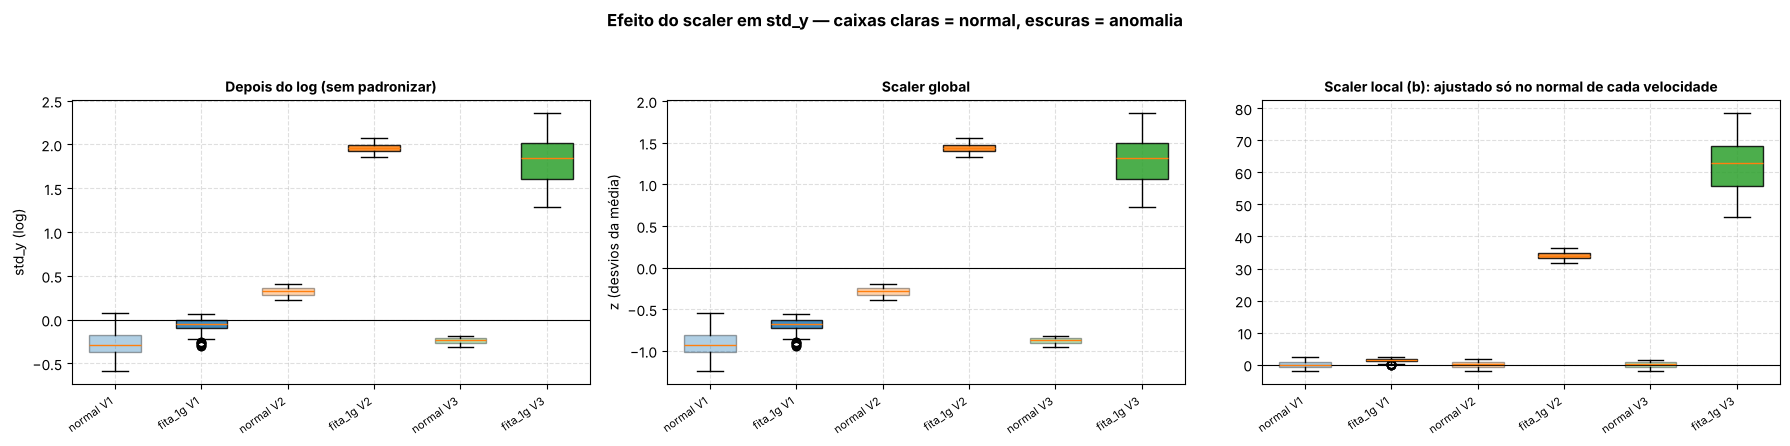

In [14]:
plotar_efeito_do_scaler(matriz_log, gabarito, "std_y")

### O que o gráfico mostra (nesta execução)

* **Depois do log, sem padronizar:** na Vel 1, normal (≈ −0,3) e fita (≈ −0,05) estão muito próximos, enquanto a fita das Vel 2 e 3 está muito acima (≈ 1,8 a 2,0).
* **Scaler global:** a régua passa a ser o desvio de todo o conjunto, dominado pela fita das Vel 2 e 3. A diferença entre normal e fita da Vel 1 vira **cerca de 0,2 desvio**, invisível perto das distâncias de 2 desvios das outras velocidades. **É isso que significa "o global esconde as magnitudes".**
* **Scaler local (b):** o normal de cada velocidade fica em volta de zero, e a régua passa a ser a variação do próprio normal. Agora a fita da Vel 1 fica a ~1,5 desvio do normal, a da Vel 2 a ~34 e a da Vel 3 a ~62.
* **Atenção:** em `std_y` sozinha, a fita da Vel 1 se afasta pouco (~1,5 desvio). A separação dela no Passo 9 vem da **combinação** de muitas features, não de uma só.

## Passo 5 — Como medir: matriz de confusão, acurácia, recall, precisão e ARI

**O que buscamos:** saber ler cada resultado sem se enganar. Esta é a parte que o orientador mais vai olhar.

### 5.1 — Primeiro problema: o K-Means não sabe nomes

O K-Means devolve números de grupo (0, 1, 2...), não "normal" ou "fita". O grupo 0 pode ser a fita numa execução e o normal em outra. Para comparar com os rótulos, **associamos cada grupo à classe com que ele mais se sobrepõe**, de forma que cada classe receba um grupo diferente e o total de acertos seja o maior possível. Esse é o **método húngaro** (`linear_sum_assignment`). Se houver mais grupos que classes, os grupos que sobram vão para a classe majoritária deles.

### 5.2 — A matriz de confusão

Uma tabela que cruza **o que a janela é de verdade** (linhas) com **o que o K-Means disse** (colunas). Exemplo inventado, só para ilustrar, com 100 janelas normais e 100 com fita:

| | disse **normal** | disse **fita** |
| --- | --- | --- |
| **é normal** | 95 (acerto) | 5 (falso alarme) |
| **é fita** | 10 (falha não detectada) | 90 (acerto) |

* **Diagonal** (95 e 90): acertos.
* **Fora da diagonal:** erros. Os 5 são **falsos alarmes** (normal acusado como fita) e os 10 são **falhas que passaram despercebidas**.

Nos gráficos deste notebook, cada célula mostra a contagem e, embaixo, a **porcentagem da linha**. A porcentagem da diagonal é o recall daquela classe.

### 5.3 — As métricas, com o mesmo exemplo

| Métrica | O que responde | Conta | No exemplo |
| --- | --- | --- | --- |
| **Acurácia** | De todas as janelas, quantas o K-Means acertou? | acertos ÷ total | (95 + 90) ÷ 200 = **92,5%** |
| **Recall da fita** (sensibilidade, taxa de detecção) | Das janelas que **são** fita, quantas foram detectadas? | 90 ÷ (90 + 10) | **90%** |
| **Recall do normal** (especificidade) | Das janelas que **são** normais, quantas foram reconhecidas como normais? | 95 ÷ (95 + 5) | **95%** |
| **Taxa de falso alarme** | Das normais, quantas foram acusadas de falha? | 5 ÷ 100 = 1 − recall do normal | **5%** |
| **Precisão da fita** | Quando o K-Means disse "fita", quantas vezes era mesmo fita? | 90 ÷ (90 + 5) | **94,7%** |
| **ARI** | O agrupamento bate com a realidade, descontando o acaso? | ver abaixo | — |

**Por que o recall é a métrica mais importante para manutenção:** uma falha não detectada (recall baixo) significa um ventilador quebrando sem aviso. Um falso alarme custa uma inspeção à toa. Por isso olhamos **recall da falha** e **falso alarme** separados, e não só a acurácia.

**Por que a acurácia sozinha engana:** imagine 190 janelas normais e 10 com fita. Um "detector" que diz sempre "normal" tem acurácia de 95%, mas **recall da fita de 0%**: não detecta nada. Aqui as classes são quase do mesmo tamanho, mas o hábito de olhar o recall vale para os dados novos.

### 5.4 — ARI (Índice de Rand Ajustado)

Olha **todos os pares de janelas** e pergunta: as duas estão juntas no mesmo grupo e também na mesma classe real? Ou separadas nos dois? Conta as concordâncias e **desconta o que se esperaria por sorte**.

* **ARI = 1:** grupos idênticos às classes.
* **ARI ≈ 0:** tão bom quanto distribuir janelas ao acaso.
* **Vantagem:** não precisa do alinhamento do 5.1, e não é enganado pelo tamanho das classes. É a métrica padrão em artigos de clusterização, então vale reportar junto.

**Atenção para não superestimar:** o alinhamento húngaro usa os rótulos para escolher o melhor "nome" de cada grupo. Isso é justo (só renomeia, não muda quem está junto com quem), mas por isso reportamos também o ARI, que não depende dele.

In [15]:
def alinhar_clusters(rotulos_reais, clusters):
    """Dá a cada grupo do K-Means o nome da classe real com que ele mais se sobrepõe (método húngaro)."""
    reais = pd.Series(np.asarray(rotulos_reais))
    grupos = pd.Series(np.asarray(clusters))
    tabela = pd.crosstab(reais, grupos)
    linhas, colunas = linear_sum_assignment(-tabela.to_numpy())
    mapa = {tabela.columns[c]: tabela.index[r] for r, c in zip(linhas, colunas)}
    for grupo in tabela.columns:
        if grupo not in mapa:
            mapa[grupo] = tabela[grupo].idxmax()
    return grupos.map(mapa).to_numpy()


def calcular_metricas(rotulos_reais, clusters, classes):
    """Acurácia, ARI, e recall e precisão de cada classe, depois do alinhamento."""
    reais = np.asarray(rotulos_reais)
    previstos = alinhar_clusters(reais, clusters)
    metricas = {"acurácia (%)": 100 * (previstos == reais).mean(), "ARI": adjusted_rand_score(reais, clusters)}
    for classe in classes:
        e_da_classe, previsto_classe = reais == classe, previstos == classe
        metricas[f"recall {classe} (%)"] = 100 * (previsto_classe & e_da_classe).sum() / max(e_da_classe.sum(), 1)
        metricas[f"precisão {classe} (%)"] = (100 * (previsto_classe & e_da_classe).sum() / previsto_classe.sum()
                                             if previsto_classe.sum() else np.nan)
    return metricas, previstos

In [16]:
def plotar_matriz_de_confusao(rotulos_reais, previstos, classes, titulo, ax=None):
    """Matriz real (linhas) x previsto (colunas): contagem e, embaixo, % da linha. A diagonal é o recall."""
    tabela = pd.crosstab(pd.Series(rotulos_reais, name="real"), pd.Series(previstos, name="previsto")).reindex(
        index=classes, columns=classes, fill_value=0)
    porcentagem = 100 * tabela.div(tabela.sum(axis=1).replace(0, np.nan), axis=0)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * len(classes) + 2.5, 1.1 * len(classes) + 1.8))
    ax.imshow(porcentagem.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100)
    for i in range(len(classes)):
        for j in range(len(classes)):
            cor = "white" if porcentagem.iat[i, j] > 60 else "black"
            ax.text(j, i, f"{tabela.iat[i, j]}\n{porcentagem.iat[i, j]:.0f}%", ha="center", va="center", fontsize=9, color=cor)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("o K-Means disse")
    ax.set_ylabel("é de verdade")
    ax.grid(False)
    acuracia = 100 * (np.asarray(previstos) == np.asarray(rotulos_reais)).mean()
    ax.set_title(f"{titulo}\nacurácia {acuracia:.1f}%", fontsize=10, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()


def plotar_pca(padronizada, rotulos_reais, clusters, titulo, rotulos_cor=None):
    """Duas vistas do mesmo PCA 2D: à esquerda as classes reais, à direita os grupos do K-Means."""
    pca = PCA(n_components=2, random_state=SEMENTE)
    pontos = pca.fit_transform(padronizada.to_numpy())
    explicada = 100 * pca.explained_variance_ratio_
    fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, rotulos, nome in ((axs[0], rotulos_reais, "classe real"), (axs[1], clusters, "grupo do K-Means")):
        rotulos = np.asarray(rotulos)
        for k, valor in enumerate(pd.unique(rotulos)):
            sel = rotulos == valor
            ax.scatter(pontos[sel, 0], pontos[sel, 1], s=14, alpha=0.7, label=str(valor), marker=MARCADORES_CONDICAO[k % len(MARCADORES_CONDICAO)])
        ax.set_xlabel(f"PC1 ({explicada[0]:.0f}% da variação)")
        ax.set_ylabel(f"PC2 ({explicada[1]:.0f}% da variação)")
        ax.set_title(f"Cor = {nome}", fontsize=10, fontweight="bold")
        ax.legend(fontsize=7, markerscale=1.4)
    fig.suptitle(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


def rodar_kmeans(padronizada, k, semente=SEMENTE):
    """Grupos do K-Means (0 a k-1) para cada janela."""
    return KMeans(n_clusters=k, n_init=N_INIT, random_state=semente).fit_predict(padronizada.to_numpy())

### 5.5 — Um "experimento" padrão

**O que buscamos:** que todos os experimentos sigam a mesma receita, para serem comparáveis. A função abaixo faz, em ordem: **(1)** pega as janelas escolhidas, **(2)** aplica o log, **(3)** padroniza com o scaler pedido, **(4)** roda o K-Means com o K pedido e **(5)** compara com o gabarito.

Ela é rodada para os quatro conjuntos de features (tempo, FFT, rotação, todas). A tabela compara os quatro, e as figuras mostram o `CONJUNTO_PRINCIPAL`.

In [17]:
def rodar_experimento(features, gabarito, selecao, colunas, k, tipo_scaler, coluna_rotulo, classes):
    """Receita padrão: log -> scaler -> K-Means -> comparação com o gabarito. Devolve um dicionário com tudo."""
    janelas = features.loc[selecao]
    rotulos = gabarito.loc[selecao]
    padronizada = padronizar(aplicar_log(janelas, colunas), rotulos, tipo_scaler)
    clusters = rodar_kmeans(padronizada, k)
    metricas, previstos = calcular_metricas(rotulos[coluna_rotulo], clusters, classes)
    return {"padronizada": padronizada, "clusters": clusters, "previstos": previstos,
            "reais": rotulos[coluna_rotulo].to_numpy(), "rotulos": rotulos, "metricas": metricas}


def comparar_conjuntos(features, gabarito, selecao, k, tipo_scaler, coluna_rotulo, classes, conjuntos=CONJUNTOS):
    """Roda o experimento em cada conjunto de features. Devolve (tabela de métricas, resultados por conjunto)."""
    resultados = {nome: rodar_experimento(features, gabarito, selecao, colunas, k, tipo_scaler, coluna_rotulo, classes)
                  for nome, colunas in conjuntos.items()}
    tabela = pd.DataFrame({nome: r["metricas"] for nome, r in resultados.items()}).T
    return tabela, resultados


RESUMO = []   # cada experimento acrescenta aqui uma linha para a tabela final


def registrar(experimento, scaler, tabela, coluna_destaque=None):
    """Guarda, para o resumo final, a acurácia e o ARI de cada conjunto de features."""
    for conjunto, linha in tabela.iterrows():
        item = {"experimento": experimento, "scaler": scaler, "features": conjunto,
                "acurácia (%)": linha["acurácia (%)"], "ARI": linha["ARI"]}
        if coluna_destaque:
            item["destaque"] = f"{coluna_destaque}: {linha[coluna_destaque]:.1f}"
        RESUMO.append(item)

## Passo 6 — K=3 só nas janelas normais: o K-Means acha as 3 velocidades?

**O que buscamos:** o primeiro teste, o mais fácil. Pegamos **só as janelas do Normal** e pedimos 3 grupos. Se os grupos baterem com as velocidades, a velocidade é a maior diferença nos dados e pode ser descoberta sem rótulo.

**Por que este passo importa para o sistema final:** o scaler local precisa saber a velocidade. Se o K-Means acha a velocidade sozinho, um primeiro modelo pode descobri-la e o segundo usa o scaler certo. Essa é a ideia da arquitetura "um modelo chama o outro".

**Scaler: global.** Aqui queremos justamente a diferença de magnitude entre as velocidades. Um scaler local, ajustado em cada velocidade, colocaria todas em volta de zero e **apagaria** a informação que procuramos.

**Como ler:** na matriz, cada linha é uma velocidade real. Diagonal cheia = cada grupo virou uma velocidade.

,acurácia (%),ARI,recall 1 (%),precisão 1 (%),recall 2 (%),precisão 2 (%),recall 3 (%),precisão 3 (%)
tempo,100.0,1.0,100.0,100.0,100.0,100.0,100.0,100.0
FFT,100.0,1.0,100.0,100.0,100.0,100.0,100.0,100.0
rotação,100.0,1.0,100.0,100.0,100.0,100.0,100.0,100.0
todas,100.0,1.0,100.0,100.0,100.0,100.0,100.0,100.0


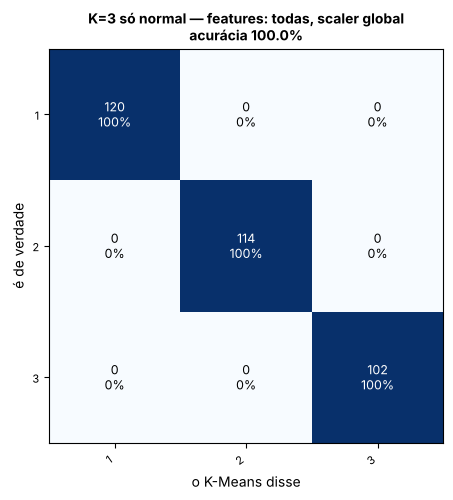

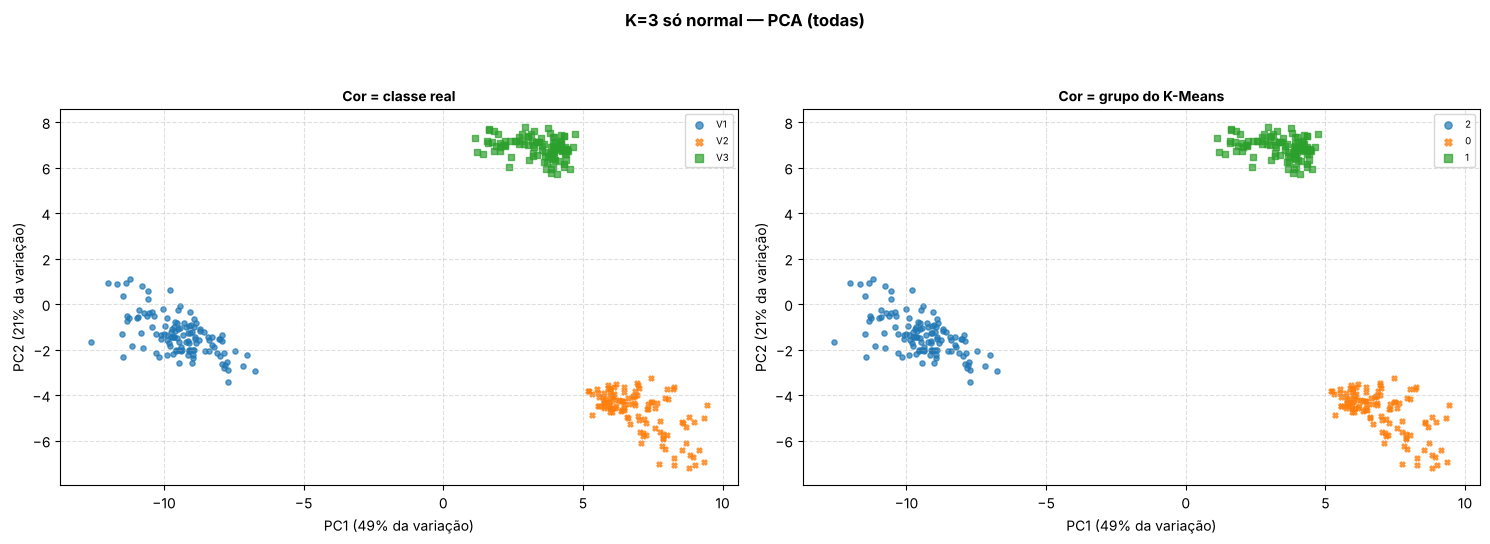

In [18]:
so_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
classes_velocidade = list(velocidades)

tabela_k3_normal, resultados_k3_normal = comparar_conjuntos(
    features, gabarito, so_normal, len(velocidades), "global", "velocidade", classes_velocidade)
registrar("K=3 só normal (velocidades)", "global", tabela_k3_normal)
display(tabela_k3_normal.round(2))

principal = resultados_k3_normal[CONJUNTO_PRINCIPAL]
plotar_matriz_de_confusao(principal["reais"], principal["previstos"], classes_velocidade,
                          f"K=3 só normal — features: {CONJUNTO_PRINCIPAL}, scaler global")
plotar_pca(principal["padronizada"], [f"V{v}" for v in principal["reais"]], principal["clusters"],
           f"K=3 só normal — PCA ({CONJUNTO_PRINCIPAL})")

### Conclusões do Passo 6 (nesta execução)

**As 3 velocidades são descobertas sem rótulo, com 100% de acerto, em qualquer conjunto de features** (tempo, FFT, rotação ou todas; ARI = 1,0). No PCA, as três nuvens do normal ficam bem separadas.

**O que isso permite:** um primeiro modelo, treinado só com o ventilador saudável, consegue dizer em que velocidade ele está. O Passo 11 confirma pelo outro lado: sem nenhum rótulo, a silhueta do normal tem o máximo em **K=3** (0,48).

## Passo 7 — K=3 só nas janelas com anomalia

**O que buscamos:** o mesmo teste do Passo 6, agora só com as janelas da falha. A falha muda a vibração. Será que ela muda tanto que as velocidades se misturam?

**Scaler:** global, pelo mesmo motivo do Passo 6.

**Com várias falhas (dados novos):** este passo junta todas as falhas. Se elas forem muito diferentes entre si, o K-Means pode separar **falhas** em vez de velocidades. Nesse caso, rode uma falha por vez em `CONDICOES_COMPARADAS`.

,acurácia (%),ARI,recall 1 (%),precisão 1 (%),recall 2 (%),precisão 2 (%),recall 3 (%),precisão 3 (%)
tempo,90.59,0.76,100.0,100.0,100.00,77.46,72.88,100.00
FFT,99.41,0.98,100.0,100.0,98.18,100.00,100.00,98.33
rotação,91.47,0.78,100.0,100.0,100.00,79.14,75.42,100.00
todas,99.41,0.98,100.0,100.0,98.18,100.00,100.00,98.33


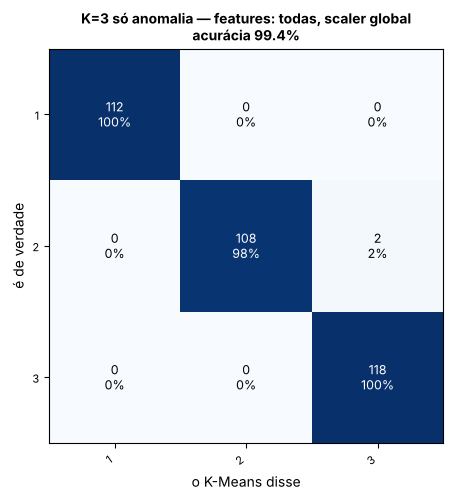

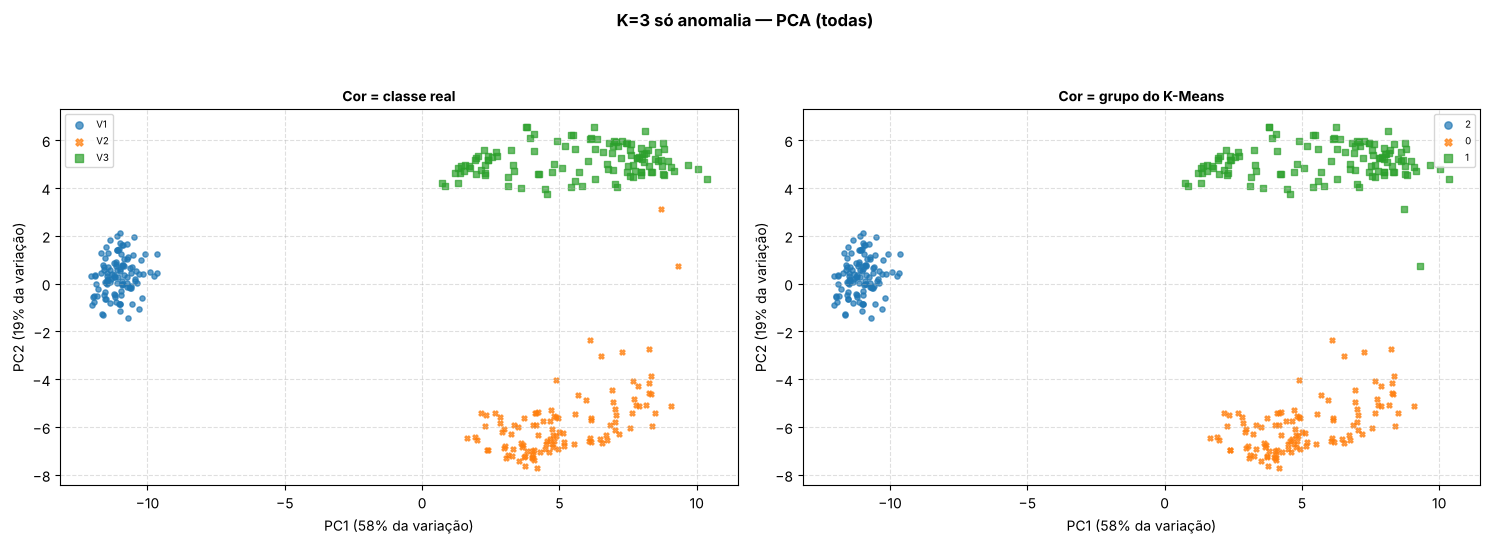

In [19]:
so_anomalia = (gabarito["binario"] == NOME_ANOMALIA).to_numpy()

tabela_k3_anomalia, resultados_k3_anomalia = comparar_conjuntos(
    features, gabarito, so_anomalia, len(velocidades), "global", "velocidade", classes_velocidade)
registrar("K=3 só anomalia (velocidades)", "global", tabela_k3_anomalia)
display(tabela_k3_anomalia.round(2))

principal = resultados_k3_anomalia[CONJUNTO_PRINCIPAL]
plotar_matriz_de_confusao(principal["reais"], principal["previstos"], classes_velocidade,
                          f"K=3 só anomalia — features: {CONJUNTO_PRINCIPAL}, scaler global")
plotar_pca(principal["padronizada"], [f"V{v}" for v in principal["reais"]], principal["clusters"],
           f"K=3 só anomalia — PCA ({CONJUNTO_PRINCIPAL})")

### Conclusões do Passo 7 (nesta execução)

**Com a fita, as velocidades continuam separáveis, mas depende das features:**

| Features | Acurácia | O que errou |
| --- | --- | --- |
| todas / FFT | **99,4%** | 2 janelas da fita V2 foram para o grupo da V3 |
| rotação | 91,5% | parte da fita V3 vai para o grupo da V2 |
| tempo | 90,6% | 32 janelas da fita V3 (27%) vão para o grupo da V2 |

* **Por quê:** a fita aumenta muito a vibração. Só com tempo (desvio, pico), uma fita na Vel 2 e uma na Vel 3 ficam parecidas em intensidade. A FFT carrega **onde** está a energia no espectro, o que depende da rotação e distingue as velocidades.
* A silhueta (Passo 11) também tem o máximo em **K=3** para a anomalia (0,53).

## Passo 8 — K=2 global: separa normal de anomalia sem saber a velocidade?

**O que buscamos:** juntar **todas as janelas** (3 velocidades, normal e falha) e pedir 2 grupos. Seria o detector mais simples possível: nem precisa saber a velocidade.

**Scaler: global** (não há velocidade conhecida nesse cenário).

**O que esperamos:** é o cenário em que o scaler global "esconde as magnitudes" (Passo 4). Nos dados antigos, ele detectou 100% da fita na Vel 2 e quase toda na Vel 3, mas **0% na Vel 1**. A maior diferença do conjunto é entre velocidades e entre a fita forte das Vel 2 e 3 e o resto; a fita da Vel 1, mais fraca, cai no grupo "normal".

**Como ler:** além da matriz geral, olhe o **recall da anomalia em cada velocidade** (tabela "por velocidade"). Uma acurácia geral alta pode esconder uma velocidade inteira não detectada.

In [20]:
def recall_por_velocidade(resultado, velocidades):
    """Recall do normal e da anomalia separado por velocidade, a partir de um resultado de K=2."""
    linhas = []
    for velocidade in velocidades:
        sel = (resultado["rotulos"]["velocidade"] == velocidade).to_numpy()
        reais, previstos = resultado["reais"][sel], resultado["previstos"][sel]
        linha = {"velocidade": velocidade}
        for classe in (NOME_NORMAL, NOME_ANOMALIA):
            e_da_classe = reais == classe
            linha[f"recall {classe} (%)"] = 100 * (previstos[e_da_classe] == classe).mean() if e_da_classe.any() else np.nan
        linha["falso alarme (%)"] = 100 - linha[f"recall {NOME_NORMAL} (%)"]
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("velocidade")

,acurácia (%),ARI,recall normal (%),precisão normal (%),recall anomalia (%),precisão anomalia (%)
tempo,83.43,0.45,100.00,75.00,67.06,100.00
FFT,83.43,0.45,100.00,75.00,67.06,100.00
rotação,51.48,-0.00,35.71,51.72,67.06,51.35
todas,83.43,0.45,100.00,75.00,67.06,100.00


Recall por velocidade (todas):


,recall normal (%),recall anomalia (%),falso alarme (%)
velocidade,,,
1,100.0,0.0,0.0
2,100.0,100.0,0.0
3,100.0,100.0,0.0


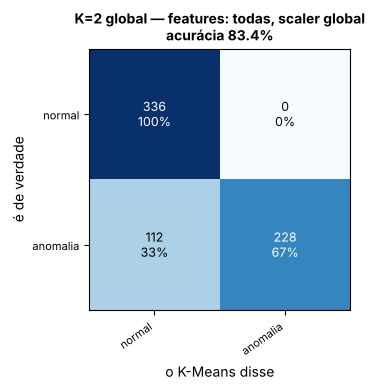

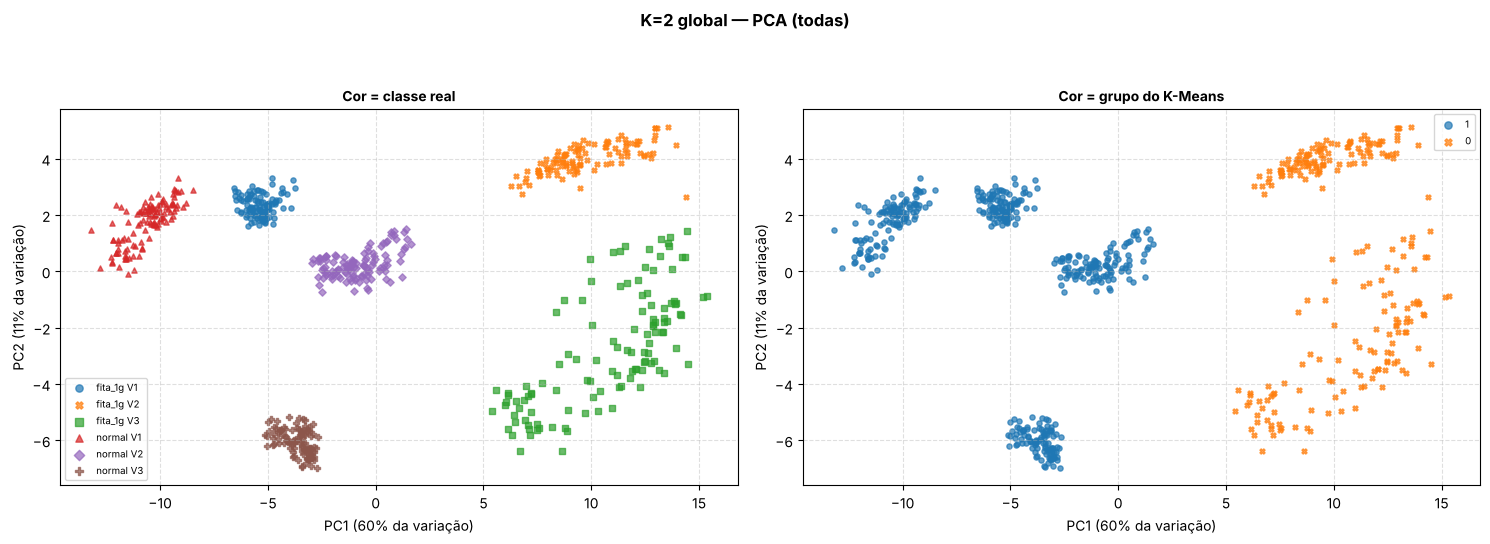

In [21]:
todas_as_janelas = np.ones(len(features), dtype=bool)
classes_binarias = [NOME_NORMAL, NOME_ANOMALIA]

tabela_k2_global, resultados_k2_global = comparar_conjuntos(
    features, gabarito, todas_as_janelas, 2, "global", "binario", classes_binarias)
registrar("K=2 global (normal x anomalia)", "global", tabela_k2_global, f"recall {NOME_ANOMALIA} (%)")
display(tabela_k2_global.round(2))

principal = resultados_k2_global[CONJUNTO_PRINCIPAL]
print(f"Recall por velocidade ({CONJUNTO_PRINCIPAL}):")
display(recall_por_velocidade(principal, velocidades).round(1))
plotar_matriz_de_confusao(principal["reais"], principal["previstos"], classes_binarias,
                          f"K=2 global — features: {CONJUNTO_PRINCIPAL}, scaler global")
plotar_pca(principal["padronizada"], principal["rotulos"]["classe"], principal["clusters"],
           f"K=2 global — PCA ({CONJUNTO_PRINCIPAL})")

### Conclusões do Passo 8 (nesta execução)

**O K=2 global repete o resultado dos dados antigos: detecta 100% da fita nas Vel 2 e 3 e 0% na Vel 1** (0 de 112 janelas), sem nenhum falso alarme. Acurácia geral de 83,4% (todas, FFT ou tempo). Só com rotação, ele separa outra coisa (51%, ARI ≈ 0).

**O PCA mostra por quê:** o primeiro eixo (60% da variação) separa a **fita das Vel 2 e 3** (à direita) **de todo o resto** (à esquerda). A fita da Vel 1 forma uma nuvem própria, mas do lado do normal. Com só 2 grupos, o K-Means escolhe a maior divisão dos dados, que é "vibra muito × vibra pouco", e não "falha × normal".

**O ponto importante:** a informação para detectar a fita da Vel 1 **existe** (ela forma uma nuvem separada, e o K=6 do Passo 10 a encontra). O problema é pedir **só 2 grupos num conjunto que tem 6**. Isso justifica separar por velocidade antes de detectar (Passo 9).

**Nem o log resolve isso** (Passo 10.3): sem log, o recall da fita V1 também é 0%.

## Passo 9 — K=2 dentro de cada velocidade, com scaler local: o teste principal

**O que buscamos:** a detecção de falha na forma em que ela seria usada: **sabendo a velocidade**, separar normal de anomalia. Para cada velocidade, separadamente:

1. pegamos só as janelas daquela velocidade;
2. aplicamos o log;
3. padronizamos com o **scaler local**;
4. rodamos K=2 e comparamos com o gabarito.

**Dois scalers, lado a lado (a diferença está explicada no Passo 4):**

* **(b) principal:** média e desvio **só do normal** daquela velocidade. Mede "o quanto a janela foge do normal".
* **(a) comparação:** média e desvio de **todas as janelas** daquela velocidade. É o que os notebooks antigos faziam.

**Como ler:** a tabela traz cada velocidade, cada scaler e cada conjunto de features. As matrizes mostram o `CONJUNTO_PRINCIPAL` com o scaler (b), uma por velocidade. O mapa de cores no fim resume o **recall da anomalia** e o **falso alarme** de todas as combinações.

In [22]:
def k2_por_velocidade(features, gabarito, tipo_scaler, conjuntos=CONJUNTOS):
    """K=2 em cada velocidade separadamente. Devolve (tabela de métricas, resultados[(velocidade, conjunto)])."""
    linhas, resultados = [], {}
    for velocidade in velocidades:
        selecao = (gabarito["velocidade"] == velocidade).to_numpy()
        for nome, colunas in conjuntos.items():
            resultado = rodar_experimento(features, gabarito, selecao, colunas, 2, tipo_scaler, "binario", classes_binarias)
            resultados[(velocidade, nome)] = resultado
            metricas = resultado["metricas"]
            linhas.append({"velocidade": velocidade, "features": nome, "scaler": tipo_scaler,
                           "acurácia (%)": metricas["acurácia (%)"], "ARI": metricas["ARI"],
                           f"recall {NOME_ANOMALIA} (%)": metricas[f"recall {NOME_ANOMALIA} (%)"],
                           "falso alarme (%)": 100 - metricas[f"recall {NOME_NORMAL} (%)"]})
    return pd.DataFrame(linhas), resultados


def juntar_velocidades(resultados, conjunto):
    """Junta os resultados das velocidades num só (para a matriz geral e o resumo)."""
    partes = [resultados[(v, conjunto)] for v in velocidades]
    reais = np.concatenate([p["reais"] for p in partes])
    previstos = np.concatenate([p["previstos"] for p in partes])
    clusters_unicos = np.concatenate([np.char.add(f"V{v}-", p["clusters"].astype(str)) for v, p in zip(velocidades, partes)])
    return reais, previstos, clusters_unicos

In [23]:
tabela_k2_local_b, resultados_k2_local_b = k2_por_velocidade(features, gabarito, "local_b")
tabela_k2_local_a, resultados_k2_local_a = k2_por_velocidade(features, gabarito, "local_a")
tabela_k2_local = pd.concat([tabela_k2_local_b, tabela_k2_local_a]).set_index(["scaler", "velocidade", "features"])
display(tabela_k2_local.round(2))

for tipo, resultados in (("local_b", resultados_k2_local_b), ("local_a", resultados_k2_local_a)):
    for conjunto in CONJUNTOS:
        reais, previstos, clusters_unicos = juntar_velocidades(resultados, conjunto)
        RESUMO.append({"experimento": "K=2 por velocidade (normal x anomalia)", "scaler": tipo, "features": conjunto,
                       "acurácia (%)": 100 * (reais == previstos).mean(),
                       "ARI": np.mean([resultados[(v, conjunto)]["metricas"]["ARI"] for v in velocidades]),
                       "destaque": f"recall {NOME_ANOMALIA} mín. entre velocidades: "
                                   f"{min(resultados[(v, conjunto)]['metricas'][f'recall {NOME_ANOMALIA} (%)'] for v in velocidades):.1f}"})

acurácia (%)   ARI  recall anomalia (%)  \
scaler  velocidade features                                            
local_b 1          tempo           100.00  1.00               100.00   
                   FFT             100.00  1.00               100.00   
                   rotação         100.00  1.00               100.00   
                   todas           100.00  1.00               100.00   
        2          tempo           100.00  1.00               100.00   
                   FFT             100.00  1.00               100.00   
                   rotação          99.55  0.98                99.09   
                   todas           100.00  1.00               100.00   
        3          tempo           100.00  1.00               100.00   
                   FFT             100.00  1.00               100.00   
                   rotação         100.00  1.00               100.00   
                   todas           100.00  1.00               100.00   
local_a 1          tempo           100.00  1.00               100.00   
                   FFT             100.00  1.00               100.00   
                   rotação         100.00  1.00               100.00   
                   todas           100.00  1.00               100.00   
        2          tempo           100.00  1.00               100.00   
                   FFT             100.00  1.00               100.00   
                   rotação         100.00  1.00               100.00   
                   todas           100.00  1.00               100.00   
        3          tempo           100.00  1.00               100.00   
                   FFT             100.00  1.00               100.00   
                   rotação         100.00  1.00               100.00   
                   todas           100.00  1.00               100.00   

                             falso alarme (%)  
scaler  velocidade features                    
local_b 1          tempo                  0.0  
                   FFT                    0.0  
                   rotação                0.0  
                   todas                  0.0  
        2          tempo                  0.0  
                   FFT                    0.0  
                   rotação                0.0  
                   todas                  0.0  
        3          tempo                  0.0  
                   FFT                    0.0  
                   rotação                0.0  
                   todas                  0.0  
local_a 1          tempo                  0.0  
                   FFT                    0.0  
                   rotação                0.0  
                   todas                  0.0  
        2          tempo                  0.0  
                   FFT                    0.0  
                   rotação                0.0  
                   todas                  0.0  
        3          tempo                  0.0  
                   FFT                    0.0  
                   rotação                0.0  
                   todas                  0.0

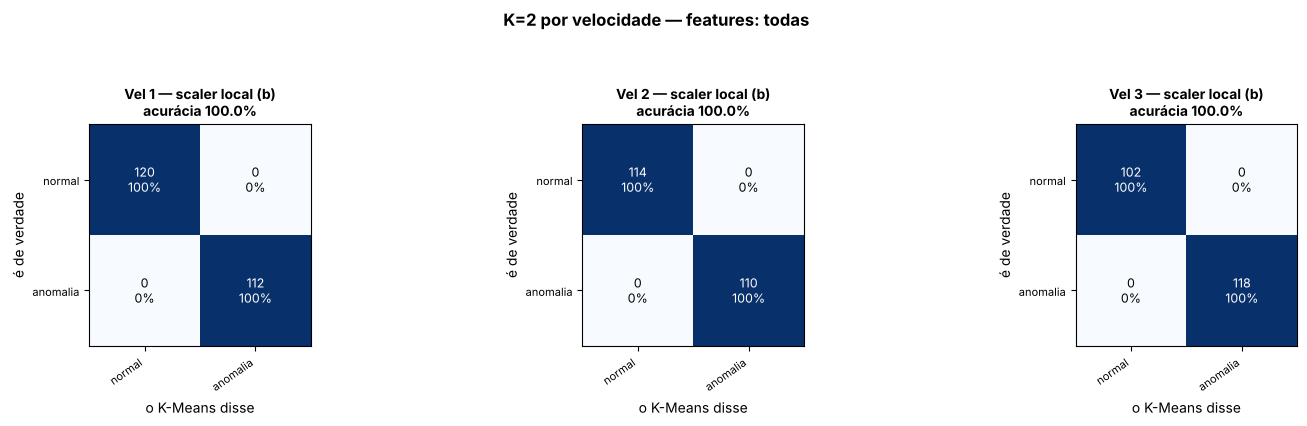

In [24]:
fig, axs = plt.subplots(1, len(velocidades), figsize=(5 * len(velocidades), 4.3))
for ax, velocidade in zip(np.atleast_1d(axs), velocidades):
    r = resultados_k2_local_b[(velocidade, CONJUNTO_PRINCIPAL)]
    plotar_matriz_de_confusao(r["reais"], r["previstos"], classes_binarias, f"Vel {velocidade} — scaler local (b)", ax=ax)
fig.suptitle(f"K=2 por velocidade — features: {CONJUNTO_PRINCIPAL}", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [25]:
def plotar_mapa_k2_local(tabela_local):
    """Dois mapas de cores (recall da anomalia e falso alarme): linhas = scaler e features, colunas = velocidade."""
    fig, axs = plt.subplots(1, 2, figsize=(14, 0.45 * len(tabela_local.index.droplevel("velocidade").unique()) + 2.5))
    for ax, medida, mapa_cor, titulo in ((axs[0], f"recall {NOME_ANOMALIA} (%)", "Greens", "Recall da anomalia (%) — maior é melhor"),
                                          (axs[1], "falso alarme (%)", "Reds", "Falso alarme (%) — menor é melhor")):
        grade = tabela_local[medida].unstack("velocidade")
        ax.imshow(grade.to_numpy(dtype=float), cmap=mapa_cor, vmin=0, vmax=100, aspect="auto")
        for i in range(grade.shape[0]):
            for j in range(grade.shape[1]):
                valor = grade.iat[i, j]
                ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=9, color="white" if valor > 60 else "black")
        ax.set_xticks(range(grade.shape[1]))
        ax.set_xticklabels([f"Vel {v}" for v in grade.columns])
        ax.set_yticks(range(grade.shape[0]))
        ax.set_yticklabels([f"{s} | {f}" for s, f in grade.index], fontsize=8)
        ax.grid(False)
        ax.set_title(titulo, fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

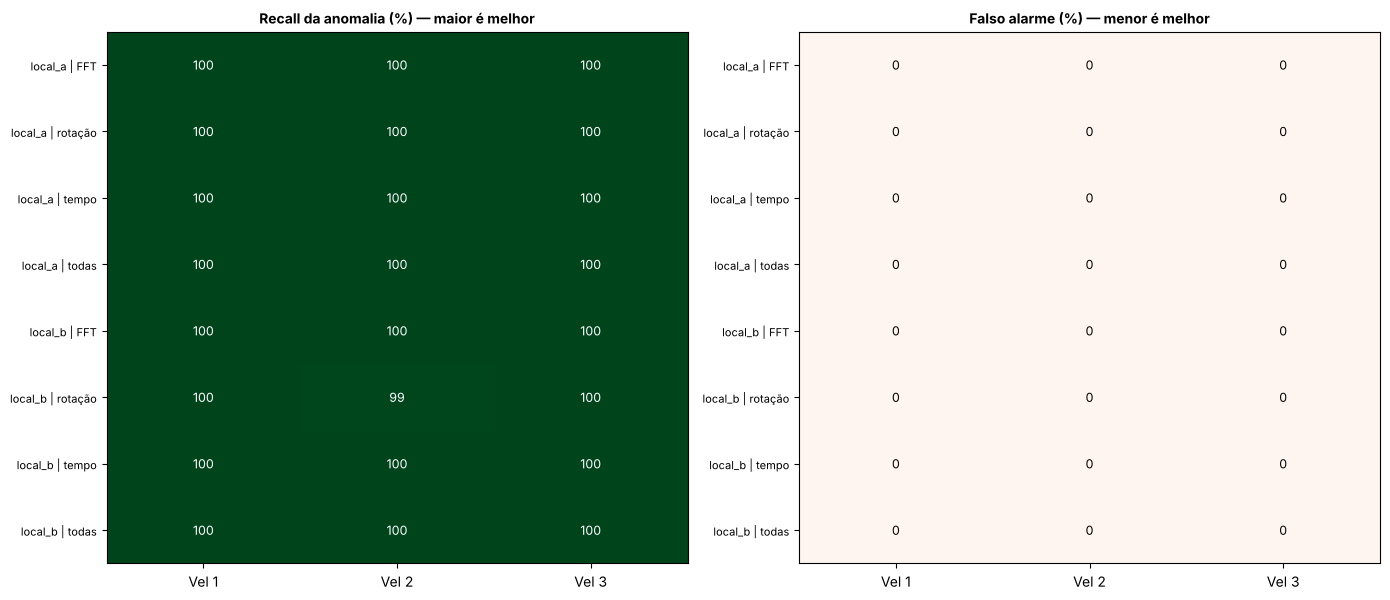

In [26]:
plotar_mapa_k2_local(tabela_k2_local)

### Conclusões do Passo 9 (nesta execução)

**Dentro de cada velocidade, o K=2 separa normal e fita com 100% de acerto, 100% de recall da anomalia e 0% de falso alarme**, nos dois scalers e em quase todos os conjuntos de features. A única exceção é rotação na Vel 2 com scaler (b): 1 janela de fita não detectada (99,5%).

* **A Vel 1, que falhava no global, passa a 100%.** Separar por velocidade resolve o problema do Passo 8.
* **Scaler (a) × (b):** nenhuma diferença com estes dados. A fita é forte o bastante para qualquer forma de padronização local. A diferença deve aparecer com falhas sutis, em que a "média da mistura" do (a) pode ficar contaminada pela falha.
* **Até um conjunto pequeno basta:** só as 9 features de tempo já dão 100%, como nos dados antigos.
* **A silhueta concorda (Passo 11):** dentro de cada velocidade, com scaler (b), o melhor K é **2** (silhuetas de 0,51, 0,77 e 0,76). Os dados se dividem naturalmente em dois grupos. Na Vel 1 a nota é a mais baixa: os dois grupos estão mais próximos.

**Cuidado ao interpretar os 100%:** cada classe aqui é **uma única gravação contínua**. Separar "normal Vel 1" de "fita Vel 1" também é separar **duas sessões de gravação**. Se algo mudou entre as sessões (posição do sensor, aperto, temperatura do motor), o K-Means também separaria. **Com estes dados não dá para distinguir "efeito da falha" de "efeito da sessão".** A nova coleta, com rodadas de Normal intercaladas, responde isso: se dois Normais de sessões diferentes também se separarem, há efeito de sessão.

## Passo 10 — K=6: velocidade e condição ao mesmo tempo

**O que buscamos:** pedir ao K-Means que separe as **6 classes** (3 velocidades × normal ou falha) de uma vez. Com mais condições nos dados novos, K = velocidades × condições, calculado sozinho.

**Por que é o teste mais difícil:** ele precisa de duas coisas que brigam entre si:

* **para separar velocidades**, precisa das magnitudes, ou seja, do scaler **global** (Passo 6);
* **para separar a falha dentro de cada velocidade**, precisa do scaler **local** (Passo 9), que apaga a diferença entre velocidades.

Nenhum scaler único faz as duas coisas. Por isso testamos cinco cenários:

| Cenário | Como funciona | Usa rótulo? |
| --- | --- | --- |
| **1. Direto, scaler global** | Um K=6 em todas as janelas | não |
| **2. Direto, scaler local (b)** | Um K=6 depois do scaler local. **Esperado: falhar**, porque o normal das 3 velocidades fica em volta de zero e vira um bolo só. Está aqui para mostrar o porquê. | velocidade e normal (para o scaler) |
| **3. Hierárquico, K=3 em todas as janelas** | **Etapa 1:** K=3 global em **todas** as janelas (normal e falha) para descobrir a velocidade. **Etapa 2:** dentro de cada grupo, scaler local (b) e K=2. | só o normal (calibração) |
| **4. Hierárquico, K=3 aprendido só no normal** | **Etapa 1:** K=3 aprendido **só com o normal** (como no Passo 6). Depois, **toda** janela, com falha ou não, é encaixada no regime de velocidade mais próximo. **Etapa 2:** igual ao 3. | só o normal (calibração) |
| **5. Hierárquico, velocidade do gabarito** | Igual ao 3, mas a velocidade vem do **gabarito**, com scaler (a). **É o que o notebook antigo fazia** e chamava de "K=6 com scaler local". | **sim, a velocidade** |

**Atenção, ponto que o orientador pode cobrar:** o cenário 5 não é um K=6 sem rótulos. A velocidade foi entregue ao algoritmo. Ele mostra o melhor caso possível (velocidade conhecida, como se o ventilador informasse a própria velocidade). **Os cenários 3 e 4 são os honestos**: tudo é descoberto, menos qual gravação é a referência normal. A diferença entre eles é **onde a velocidade é aprendida**. No 3, a falha participa da etapa 1 e pode "roubar" um grupo de velocidade. No 4, os regimes de velocidade são aprendidos só com o ventilador saudável, e a falha só é encaixada depois. Se o 4 chegar perto do 5, a velocidade pode mesmo ser descoberta sem medidor de rotação.

**Grupo sem normal:** se um grupo da etapa 1 não tiver nenhuma janela normal, não dá para calibrar o scaler (b) nele. O grupo inteiro vira um grupo final só, e o código avisa. Para um detector isso faz sentido: aquelas janelas não se parecem com nenhum regime normal conhecido.

**O cenário 4 é a arquitetura "um modelo chama o outro"** em versão não supervisionada: o primeiro modelo descobre a velocidade e chama o detector daquela velocidade.

In [27]:
def k6_hierarquico(features, gabarito, colunas, grupos_velocidade, tipo_ajuste):
    """Etapa 1 já feita (grupos_velocidade); etapa 2: scaler local por grupo e K=(nº de condições) em cada grupo.

    tipo_ajuste: 'b' (scaler ajustado só nas normais do grupo) ou 'a' (todas as janelas do grupo).
    Devolve os grupos finais, como textos 'grupo-subgrupo'.

    Se um grupo da etapa 1 não tiver nenhuma janela normal, não há como calibrar o scaler (b) nele.
    Nesse caso o grupo inteiro vira um único grupo final ('grupo-sem_normal'): ele não se parece com
    nenhum regime normal conhecido, o que para um detector já é sinal de anomalia.
    """
    matriz = aplicar_log(features, colunas)
    grupos = np.asarray(grupos_velocidade)
    e_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
    finais = np.empty(len(matriz), dtype=object)
    for grupo in pd.unique(grupos):
        sel = grupos == grupo
        ajuste = sel & e_normal if tipo_ajuste == "b" else sel
        if ajuste.sum() < 2:
            finais[sel] = f"{grupo}-sem_normal"
            print(f"  aviso: o grupo {grupo} da etapa 1 ({sel.sum()} janelas) não tem janelas normais para calibrar o scaler (b)")
            continue
        scaler = StandardScaler().fit(matriz[ajuste])
        padronizada = pd.DataFrame(scaler.transform(matriz[sel]), index=matriz.index[sel], columns=matriz.columns)
        sub = rodar_kmeans(padronizada, len(ORDEM_CONDICOES))
        finais[sel] = [f"{grupo}-{s}" for s in sub]
    return finais

In [28]:
def descobrir_velocidade_pelo_normal(matriz, e_normal, k):
    """Aprende K regimes de velocidade só com as janelas normais e encaixa todas as janelas no regime mais próximo.

    O scaler global e o K-Means são ajustados só no normal; as janelas com falha só são classificadas.
    """
    scaler = StandardScaler().fit(matriz[e_normal])
    modelo = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMENTE).fit(scaler.transform(matriz[e_normal]))
    return modelo.predict(scaler.transform(matriz))

In [29]:
k6 = len(ORDEM_CLASSES)
resultados_k6, linhas_k6, etapa1 = {}, [], {}

for conjunto, colunas in CONJUNTOS.items():
    print(f"features: {conjunto}")
    matriz = aplicar_log(features, colunas)
    cenarios = {}
    cenarios["direto, scaler global"] = rodar_kmeans(padronizar_global(matriz), k6)
    cenarios["direto, scaler local (b)"] = rodar_kmeans(padronizar(matriz, gabarito, "local_b"), k6)
    e_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
    velocidade_em_tudo = rodar_kmeans(padronizar_global(matriz), len(velocidades))
    cenarios["hierárquico, K=3 em todas as janelas, scaler (b)"] = k6_hierarquico(features, gabarito, colunas, velocidade_em_tudo, "b")
    velocidade_pelo_normal = descobrir_velocidade_pelo_normal(matriz, e_normal, len(velocidades))
    etapa1[(conjunto, "K=3 em todas as janelas")] = velocidade_em_tudo
    etapa1[(conjunto, "K=3 aprendido só no normal")] = velocidade_pelo_normal
    cenarios["hierárquico, K=3 aprendido só no normal, scaler (b)"] = k6_hierarquico(features, gabarito, colunas, velocidade_pelo_normal, "b")
    cenarios["hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]"] = k6_hierarquico(
        features, gabarito, colunas, gabarito["velocidade"], "a")
    for nome, clusters in cenarios.items():
        metricas, previstos = calcular_metricas(gabarito["classe"], clusters, ORDEM_CLASSES)
        resultados_k6[(conjunto, nome)] = {"clusters": clusters, "previstos": previstos, "metricas": metricas}
        linhas_k6.append({"features": conjunto, "cenário": nome, "acurácia (%)": metricas["acurácia (%)"], "ARI": metricas["ARI"]})
        RESUMO.append({"experimento": f"K={k6} (velocidade x condição)", "scaler": nome, "features": conjunto,
                       "acurácia (%)": metricas["acurácia (%)"], "ARI": metricas["ARI"]})

tabela_k6 = pd.DataFrame(linhas_k6).set_index(["cenário", "features"])
display(tabela_k6.round(2))

features: tempo
  aviso: o grupo 2 da etapa 1 (142 janelas) não tem janelas normais para calibrar o scaler (b)
  aviso: o grupo 0 da etapa 1 (86 janelas) não tem janelas normais para calibrar o scaler (b)


features: FFT
  aviso: o grupo 1 da etapa 1 (228 janelas) não tem janelas normais para calibrar o scaler (b)


features: rotação
  aviso: o grupo 0 da etapa 1 (228 janelas) não tem janelas normais para calibrar o scaler (b)


features: todas
  aviso: o grupo 1 da etapa 1 (228 janelas) não tem janelas normais para calibrar o scaler (b)


,,acurácia (%),ARI
cenário,features,,
"direto, scaler global",tempo,79.44,0.78
"direto, scaler local (b)",tempo,59.91,0.51
"hierárquico, K=3 em todas as janelas, scaler (b)",tempo,63.61,0.51
"hierárquico, K=3 aprendido só no normal, scaler (b)",tempo,75.44,0.68
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",tempo,100.00,1.00
"direto, scaler global",FFT,99.70,0.99
"direto, scaler local (b)",FFT,57.69,0.51
"hierárquico, K=3 em todas as janelas, scaler (b)",FFT,83.73,0.82
"hierárquico, K=3 aprendido só no normal, scaler (b)",FFT,82.69,0.81


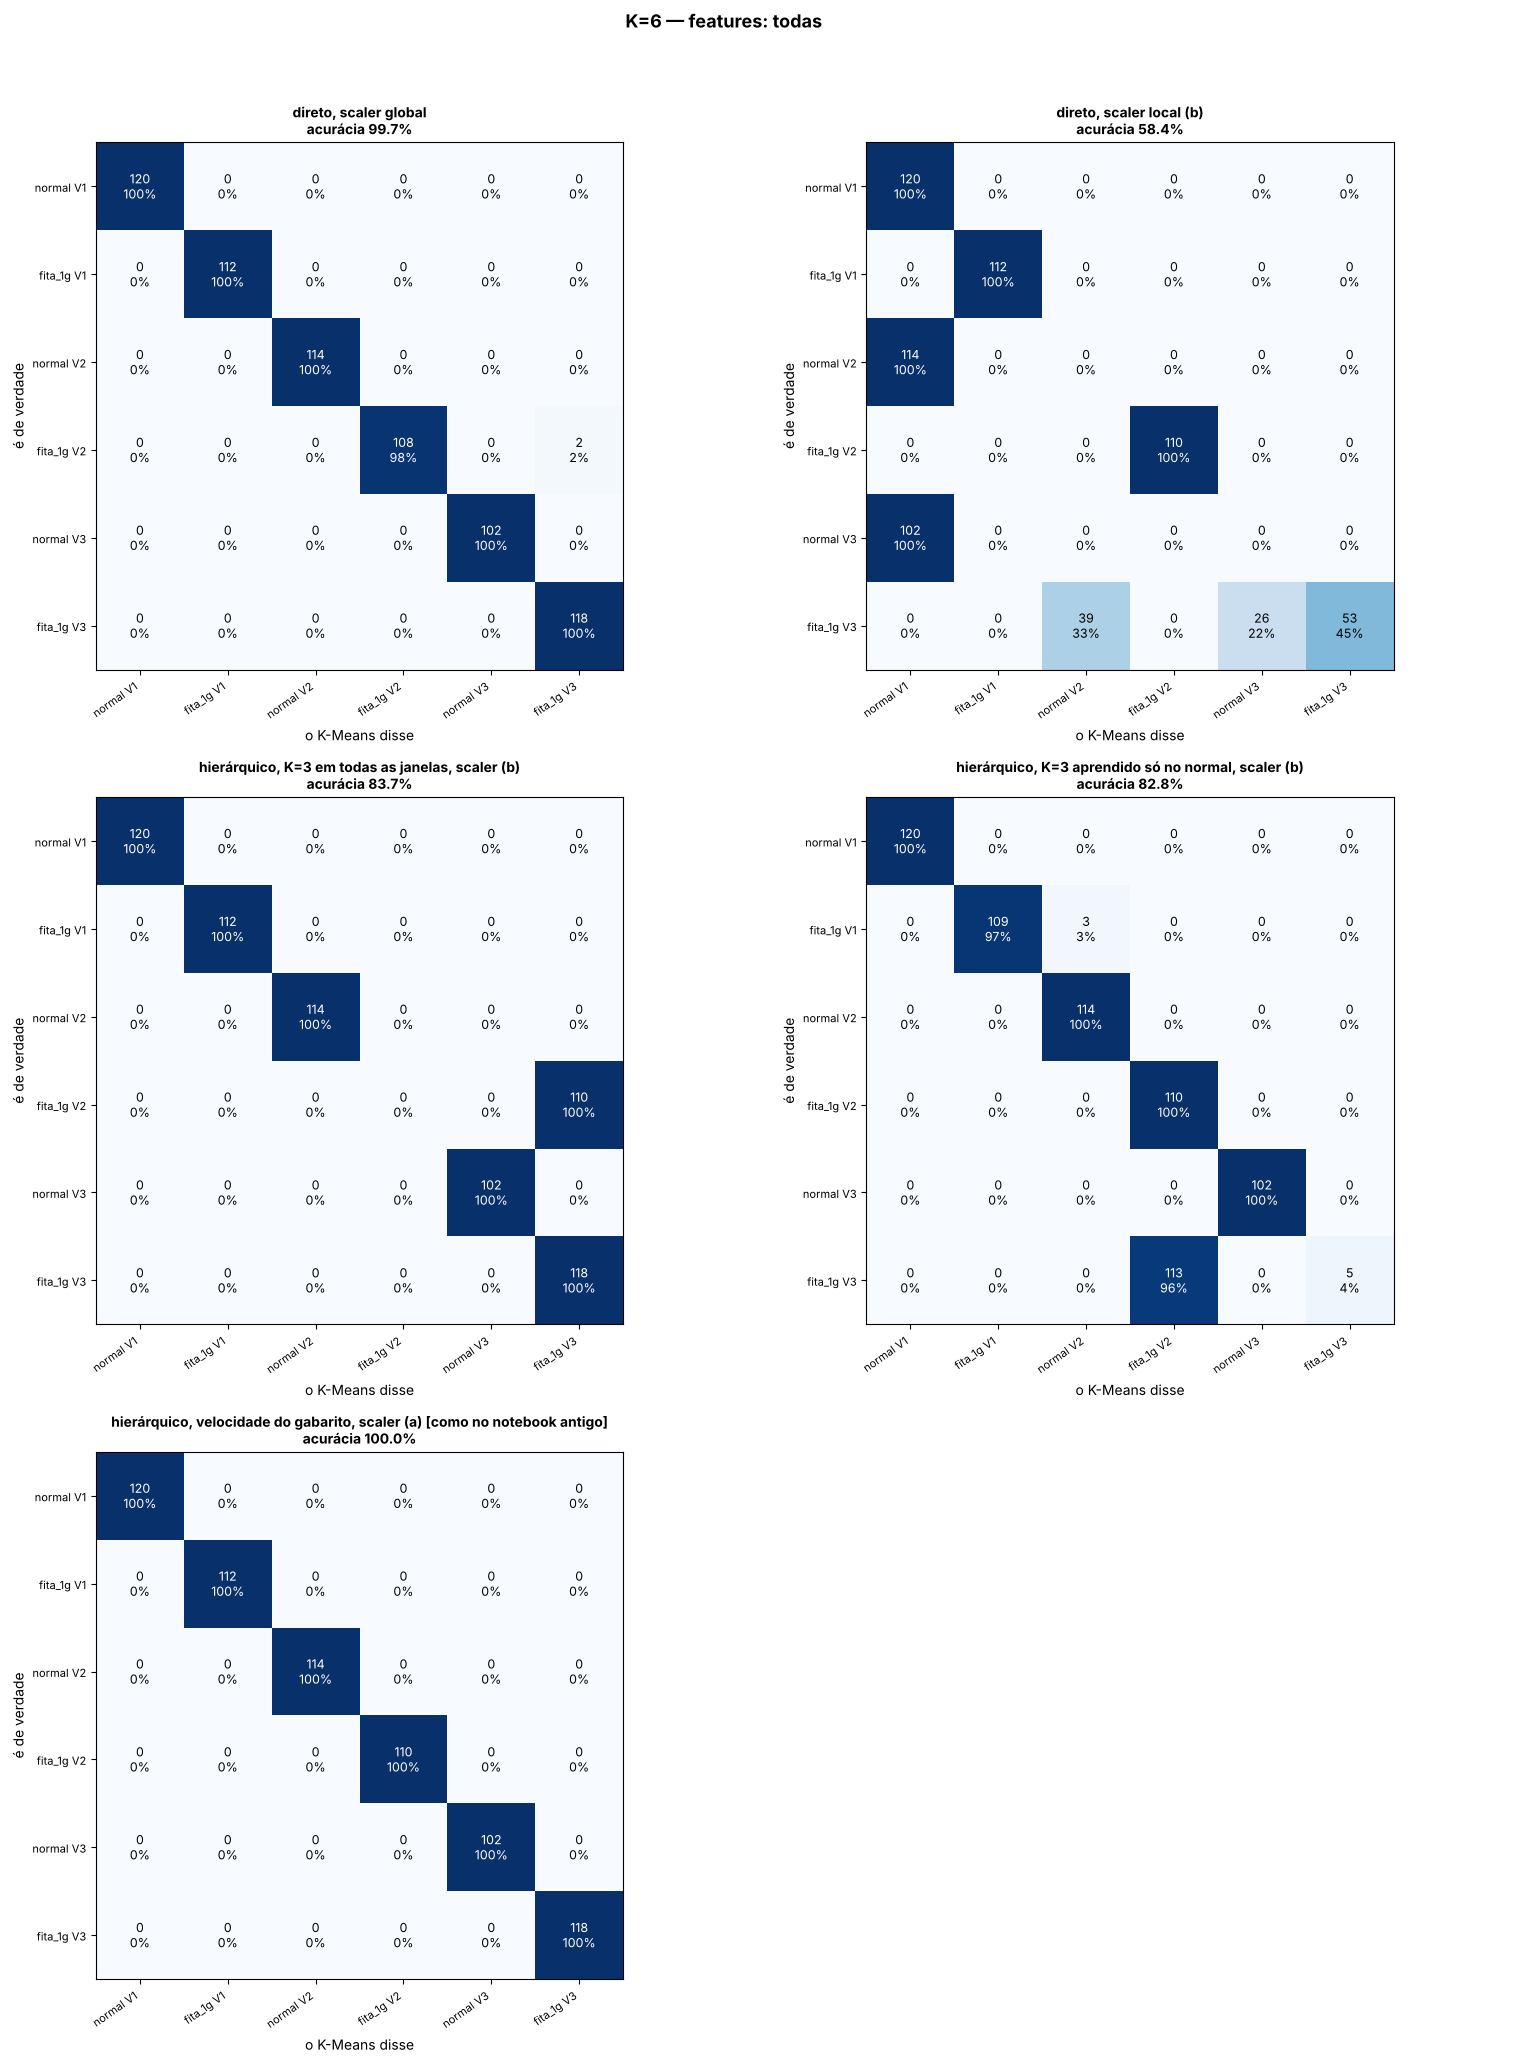

In [30]:
nomes_k6 = list(dict.fromkeys(n for _, n in resultados_k6))
fig, axs = plt.subplots(3, 2, figsize=(16, 21))
axs.ravel()[-1].axis("off")
for ax, nome in zip(axs.ravel(), nomes_k6):
    r = resultados_k6[(CONJUNTO_PRINCIPAL, nome)]
    plotar_matriz_de_confusao(gabarito["classe"].to_numpy(), r["previstos"], ORDEM_CLASSES, nome, ax=ax)
fig.suptitle(f"K={k6} — features: {CONJUNTO_PRINCIPAL}", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 10.1 — Etapa 1: em qual regime de velocidade cada classe caiu?

**O que buscamos:** entender por que os cenários hierárquicos 3 e 4 perdem acurácia. A tabela cruza a classe real (linhas) com o regime de velocidade escolhido na etapa 1 (colunas, numerados pelo K-Means).

* **Ideal:** cada velocidade real, normal e falha, cai num regime só e diferente dos outros.
* **Se a falha de uma velocidade cair no regime de outra,** a etapa 2 vai juntá-la com a falha daquela outra velocidade. O K=6 erra a **velocidade** dessa falha, mas ela ainda pode ser **detectada** como anomalia (10.2).

In [31]:
for nome in ("K=3 em todas as janelas", "K=3 aprendido só no normal"):
    print(f"Etapa 1 — {nome} (features: {CONJUNTO_PRINCIPAL})")
    display(pd.crosstab(gabarito["classe"], etapa1[(CONJUNTO_PRINCIPAL, nome)], rownames=["classe real"], colnames=["regime"]).reindex(ORDEM_CLASSES))

Etapa 1 — K=3 em todas as janelas (features: todas)


regime,0,1,2
classe real,,,
normal V1,0,0,120
fita_1g V1,0,0,112
normal V2,114,0,0
fita_1g V2,0,110,0
normal V3,102,0,0
fita_1g V3,0,118,0


Etapa 1 — K=3 aprendido só no normal (features: todas)


regime,0,1,2
classe real,,,
normal V1,0,0,120
fita_1g V1,3,0,109
normal V2,114,0,0
fita_1g V2,110,0,0
normal V3,0,102,0
fita_1g V3,113,5,0


### 10.2 — Os cenários hierárquicos usados como detector (normal × anomalia)

**O que buscamos:** para a manutenção, o mais importante é **detectar** a falha, mesmo que a velocidade atribuída a ela esteja errada. Transformamos os 6 grupos em "normal" ou "anomalia" com uma regra que **não usa o gabarito da falha**, só a referência normal (a mesma informação que o scaler b já usa):

* em cada regime de velocidade, o subgrupo que contém a **maior parte das janelas normais de calibração** é o "normal";
* todos os outros subgrupos, e os regimes sem nenhuma janela normal, são "anomalia".

**Como ler:** recall da anomalia alto e falso alarme baixo = o detector funciona, mesmo que o K=6 tenha errado a velocidade de alguma falha.

In [32]:
def detectar_pelos_grupos(grupos_finais, e_normal):
    """Converte os grupos do hierárquico em normal/anomalia: em cada regime, o subgrupo com mais normais é o normal."""
    grupos = pd.Series(grupos_finais).astype(str)
    regime = grupos.str.split("-").str[0]
    decisao = pd.Series(NOME_ANOMALIA, index=grupos.index)
    for r in regime.unique():
        normais_no_regime = grupos[(regime == r).to_numpy() & e_normal]
        if len(normais_no_regime):
            decisao[grupos == normais_no_regime.value_counts().idxmax()] = NOME_NORMAL
    return decisao.to_numpy()

In [33]:
e_normal = (gabarito["binario"] == NOME_NORMAL).to_numpy()
linhas_detector = []
for (conjunto, nome), r in resultados_k6.items():
    if not nome.startswith("hierárquico"):
        continue
    decisao = detectar_pelos_grupos(r["clusters"], e_normal)
    reais = gabarito["binario"].to_numpy()
    linha = {"cenário": nome, "features": conjunto}
    for velocidade in velocidades:
        sel = (gabarito["velocidade"] == velocidade).to_numpy() & (reais == NOME_ANOMALIA)
        linha[f"recall anomalia V{velocidade} (%)"] = 100 * (decisao[sel] == NOME_ANOMALIA).mean()
    linha[f"recall anomalia geral (%)"] = 100 * (decisao[reais == NOME_ANOMALIA] == NOME_ANOMALIA).mean()
    linha["falso alarme (%)"] = 100 * (decisao[reais == NOME_NORMAL] == NOME_ANOMALIA).mean()
    linhas_detector.append(linha)
tabela_detector = pd.DataFrame(linhas_detector).set_index(["cenário", "features"])
display(tabela_detector.round(1))

,,recall anomalia V1 (%),recall anomalia V2 (%),recall anomalia V3 (%),recall anomalia geral (%),falso alarme (%)
cenário,features,,,,,
"hierárquico, K=3 em todas as janelas, scaler (b)",tempo,0.0,100.0,100.0,67.1,33.9
"hierárquico, K=3 aprendido só no normal, scaler (b)",tempo,36.6,100.0,100.0,79.1,0.0
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",tempo,100.0,100.0,100.0,100.0,0.0
"hierárquico, K=3 em todas as janelas, scaler (b)",FFT,100.0,100.0,100.0,100.0,30.4
"hierárquico, K=3 aprendido só no normal, scaler (b)",FFT,96.4,100.0,100.0,98.8,0.0
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",FFT,100.0,100.0,100.0,100.0,0.0
"hierárquico, K=3 em todas as janelas, scaler (b)",rotação,100.0,100.0,100.0,100.0,30.7
"hierárquico, K=3 aprendido só no normal, scaler (b)",rotação,96.4,0.0,95.8,65.0,13.7
"hierárquico, velocidade do gabarito, scaler (a) [como no notebook antigo]",rotação,100.0,100.0,100.0,100.0,0.0


### 10.3 — Com e sem log: o que o log mudou?

**O que buscamos:** isolar o efeito do log do Passo 3. Repetimos os dois experimentos com scaler global (K=6 direto e K=2 global) **sem aplicar o log**, nos mesmos dados.

**Por que isso importa:** o notebook antigo não usava log e teve **56,51%** no K=6 global. Se o resultado sem log aqui ficar parecido, e o com log bem maior, a melhora vem do log, e não de diferenças entre as bases.

In [34]:
def comparar_com_e_sem_log(features, gabarito, conjuntos=CONJUNTOS):
    """K=6 direto e K=2 global, com scaler global, com e sem log."""
    linhas = []
    anomalia_v1 = ((gabarito["velocidade"] == velocidades[0]) & (gabarito["binario"] == NOME_ANOMALIA)).to_numpy()
    for usar_log in (True, False):
        for nome, colunas in conjuntos.items():
            padronizada = padronizar_global(aplicar_log(features, colunas, aplicar=usar_log))
            metricas_k6, _ = calcular_metricas(gabarito["classe"], rodar_kmeans(padronizada, len(ORDEM_CLASSES)), ORDEM_CLASSES)
            metricas_k2, previstos_k2 = calcular_metricas(gabarito["binario"], rodar_kmeans(padronizada, 2), classes_binarias)
            linhas.append({"log": "com log" if usar_log else "sem log", "features": nome,
                           f"K={len(ORDEM_CLASSES)} direto, acurácia (%)": metricas_k6["acurácia (%)"],
                           "K=2 global, acurácia (%)": metricas_k2["acurácia (%)"],
                           f"K=2 global, recall anomalia V{velocidades[0]} (%)": 100 * (previstos_k2[anomalia_v1] == NOME_ANOMALIA).mean()})
    return pd.DataFrame(linhas).set_index(["features", "log"]).sort_index()

In [35]:
display(comparar_com_e_sem_log(features, gabarito).round(2))

K=6 direto, acurácia (%)  K=2 global, acurácia (%)  \
features log                                                           
FFT      com log                     99.70                     83.43   
         sem log                     60.36                     78.85   
rotação  com log                     95.27                     51.48   
         sem log                     57.25                     83.28   
tempo    com log                     79.44                     83.43   
         sem log                     71.01                     83.28   
todas    com log                     99.70                     83.43   
         sem log                     57.40                     82.69   

                  K=2 global, recall anomalia V1 (%)  
features log                                          
FFT      com log                                 0.0  
         sem log                                 0.0  
rotação  com log                                 0.0  
         sem log                                 0.0  
tempo    com log                                 0.0  
         sem log                                 0.0  
todas    com log                                 0.0  
         sem log                                 0.0

### Conclusões do Passo 10 (nesta execução)

**O resultado mais surpreendente do notebook: com log, o K=6 direto com scaler global separa as 6 classes com 99,7%** (todas ou FFT; só 2 janelas da fita V2 foram para o grupo da fita V3).

| Cenário (features: todas) | K=6, acurácia | Como detector: recall da anomalia | Falso alarme |
| --- | --- | --- | --- |
| 1. Direto, scaler global | **99,7%** | — | — |
| 2. Direto, scaler local (b) | 58,4% | — | — |
| 3. Hierárquico, K=3 em todas as janelas | 83,7% | 100% | **30,4%** |
| 4. Hierárquico, K=3 aprendido só no normal | 82,8% | **99,1%** | **0%** |
| 5. Hierárquico, velocidade do gabarito (notebook antigo) | 100% | 100% | 0% |

**1. O log é o que faz o K=6 funcionar (10.3).** Sem log, o K=6 global dá **57,4%**, praticamente os 56,5% do notebook antigo. Com log, 99,7%. Sem log, as nuvens enormes da fita V2 e V3 dominam as distâncias e "roubam" os centros. O log põe todas as classes numa escala comparável.

**2. O scaler local direto (cenário 2) falha, como esperado:** as 336 janelas normais das 3 velocidades caem **num grupo só**, porque o scaler (b) põe o normal de cada velocidade em volta de zero. Os grupos que sobram são gastos dividindo a fita V3. **O scaler local apaga a velocidade, então não serve para um K=6 direto.**

**3. Os cenários hierárquicos honestos (3 e 4) erram a velocidade de uma falha, mas por motivos diferentes (10.1):**

* **Cenário 3:** o K=3 em todas as janelas junta o normal V2 com o normal V3, e a fita V2 com a fita V3. Na etapa 2, o K=2 divide "normal V2 × normal V3" e acusa um deles de anomalia: **30% de falso alarme**.
* **Cenário 4:** os regimes aprendidos só no normal estão certos para o normal (100%), mas **113 das 118 janelas da fita V3 caem no regime da Vel 2**. A fita na Vel 3 fica mais parecida com o regime da Vel 2 do que com o da Vel 3. O K=6 junta as duas fitas, mas **como detector ele funciona: 99,1% de recall e nenhum falso alarme**. Só escapam 3 janelas da fita V1, que caíram no regime da Vel 2.

**4. O cenário 5 (como no notebook antigo) dá 100%, mas recebeu a velocidade do gabarito.** O "K=6 com scaler local 100%" antigo deve ser descrito assim no TCC: **velocidade conhecida + K=2 por velocidade**, e não um K=6 sem rótulos.

**O que isso significa para a arquitetura:**

* **Para detectar** ("está com falha?"), o cenário 4 já funciona sem medir a rotação: aprende os regimes no normal, encaixa a janela e compara com o normal daquele regime.
* **Para dizer a velocidade de uma janela com falha**, os regimes aprendidos no normal não são confiáveis: a falha muda o sinal o bastante para enganar. Se a velocidade for necessária no diagnóstico, ela precisa ser medida ou classificada com rótulos (Notebook 05).

## Passo 11 — Silhueta: quantos grupos os dados "pedem", sem olhar rótulos?

**O que buscamos:** até aqui nós **dissemos** ao K-Means quantos grupos procurar (3, 2, 6). Agora perguntamos o contrário: **se não soubéssemos nada, qual K os próprios dados indicariam?**

**O que é a silhueta:** para cada janela, compara a distância média até as janelas **do próprio grupo** com a distância até o **grupo vizinho mais próximo**.

* **Perto de 1:** a janela está bem dentro do seu grupo e longe dos outros.
* **Perto de 0:** está na fronteira entre dois grupos.
* **Negativa:** provavelmente está no grupo errado.

A silhueta média de todas as janelas dá uma nota para cada K. **O K com a maior nota é o que os dados sugerem.**

**Como ler:** se a curva tem o pico em K=2 dentro de cada velocidade (scaler local b), os dados se dividem naturalmente em dois grupos, o que bate com normal e falha. Se o pico estiver em outro K (por exemplo, 4), pode haver subgrupos escondidos, como a fase do ciclo ou o início e o fim de uma gravação com deriva.

In [36]:
def calcular_silhuetas(padronizada, valores_k=K_SILHUETA):
    """Silhueta média para cada K."""
    return pd.Series({k: silhouette_score(padronizada.to_numpy(), rodar_kmeans(padronizada, k)) for k in valores_k})

,"só normal, scaler global","só anomalia, scaler global","todas, scaler global","Vel 1, scaler local (b)","Vel 2, scaler local (b)","Vel 3, scaler local (b)"
2,0.434,0.515,0.451,0.507,0.774,0.757
3,0.479,0.526,0.386,0.343,0.548,0.591
4,0.404,0.496,0.406,0.202,0.550,0.571
5,0.350,0.452,0.434,0.208,0.241,0.531
6,0.269,0.450,0.457,0.208,0.216,0.507
7,0.253,0.299,0.448,0.171,0.208,0.499
8,0.253,0.258,0.427,0.166,0.220,0.208


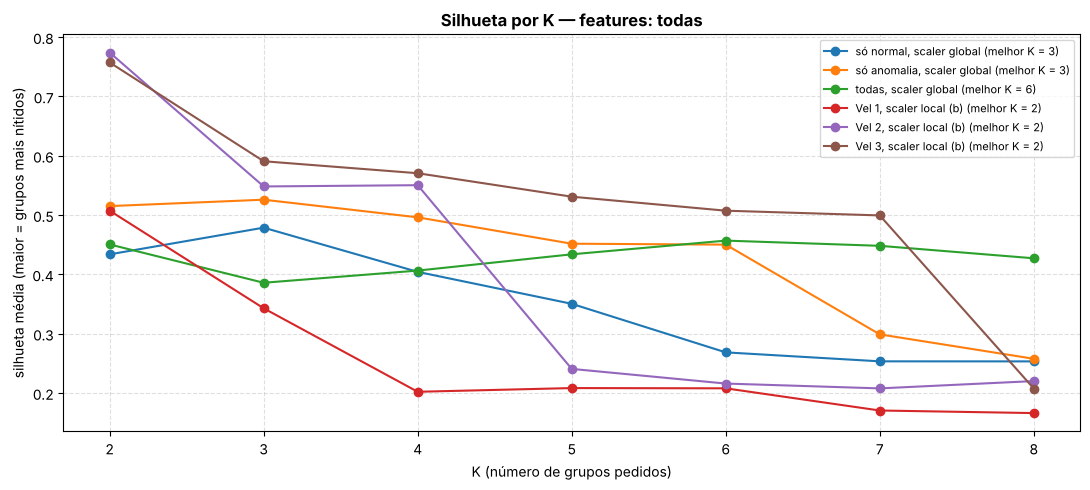

In [37]:
curvas = {}
matriz_principal = aplicar_log(features, CONJUNTOS[CONJUNTO_PRINCIPAL])
curvas["só normal, scaler global"] = calcular_silhuetas(padronizar_global(matriz_principal.loc[so_normal]))
curvas["só anomalia, scaler global"] = calcular_silhuetas(padronizar_global(matriz_principal.loc[so_anomalia]))
curvas["todas, scaler global"] = calcular_silhuetas(padronizar_global(matriz_principal))
for velocidade in velocidades:
    sel = (gabarito["velocidade"] == velocidade).to_numpy()
    curvas[f"Vel {velocidade}, scaler local (b)"] = calcular_silhuetas(padronizar(matriz_principal.loc[sel], gabarito.loc[sel], "local_b"))

silhuetas = pd.DataFrame(curvas)
display(silhuetas.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
for nome in silhuetas.columns:
    ax.plot(silhuetas.index, silhuetas[nome], marker="o", label=f"{nome} (melhor K = {silhuetas[nome].idxmax()})")
ax.set_xlabel("K (número de grupos pedidos)")
ax.set_ylabel("silhueta média (maior = grupos mais nítidos)")
ax.set_title(f"Silhueta por K — features: {CONJUNTO_PRINCIPAL}", fontsize=12, fontweight="bold")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Conclusões do Passo 11 (nesta execução)

**Sem nenhum rótulo, os dados "pedem" exatamente o número de grupos que esperávamos:**

| Dados | Melhor K | Silhueta | Esperado |
| --- | --- | --- | --- |
| só normal | **3** | 0,48 | 3 velocidades ✓ |
| só anomalia | **3** | 0,53 | 3 velocidades ✓ |
| todas as janelas | **6** | 0,46 | 6 classes ✓ (mas K=2 fica logo atrás, 0,45) |
| Vel 1, scaler local (b) | **2** | 0,51 | normal e fita ✓ |
| Vel 2, scaler local (b) | **2** | 0,77 | normal e fita ✓ |
| Vel 3, scaler local (b) | **2** | 0,76 | normal e fita ✓ |

* **O que isso diz:** a estrutura dos dados é a estrutura das condições. Nenhum K "estranho" (como 4) aparece com nota alta, então não há subgrupos escondidos fortes, como a fase do ciclo, que o K-Means preferisse separar.
* **Todas as janelas:** K=6 e K=2 quase empatam (0,46 e 0,45). Isso explica o Passo 8: a divisão em 2 grupos ("vibra muito × vibra pouco") também é bem nítida, e o K=2 a escolhe.
* **Vel 1** tem a menor nota (0,51): normal e fita estão mais próximos nela do que nas outras velocidades. É a velocidade mais difícil, como nos notebooks anteriores.

## Passo 12 — Checagens anti-ilusão

**O que buscamos:** ter certeza de que um bom resultado vem **da falha** e não de algum efeito paralelo nos dados. São quatro checagens:

1. **Erros no tempo (12.1):** onde, ao longo da gravação, o K-Means erra?
2. **Deriva e fase (12.2):** o Normal sozinho já se divide em dois grupos?
3. **Estabilidade (12.3):** o resultado depende do sorteio inicial do K-Means?
4. **Janelas atípicas (12.4):** poucas janelas estranhas estão puxando o resultado?

### 12.1 — Erros no tempo

**Como ler o gráfico:** cada faixa é uma gravação, com as janelas em ordem de tempo (da esquerda para a direita). O ponto fica em cima se o K-Means disse "anomalia" e embaixo se disse "normal". **Verde = acerto, X vermelho = erro.**

O que procurar:

* **Erros espalhados e raros:** ruído normal.
* **Erros juntos no começo ou no fim:** problema na gravação (manuseio, aquecimento).
* **Erros alternando (uma sim, uma não):** o ciclo da oscilação. Com janelas de 5 s e ciclo de ~10 s, as janelas alternam fase forte e fraca (Notebook 03).
* **Uma gravação inteira errada:** o grupo não separou aquela condição.

In [38]:
def plotar_erros_no_tempo(resultados_por_velocidade, conjunto, gabarito):
    """Para cada base: o que o K-Means disse em cada janela, na ordem do tempo. Verde = acerto, vermelho = erro."""
    bases_ordenadas = gabarito[["base", "velocidade", "condicao"]].drop_duplicates().sort_values(["velocidade", "condicao"])
    fig, axs = plt.subplots(len(bases_ordenadas), 1, figsize=(14, 1.25 * len(bases_ordenadas) + 1), sharex=True, squeeze=False)
    for ax, (_, linha) in zip(axs[:, 0], bases_ordenadas.iterrows()):
        r = resultados_por_velocidade[(linha["velocidade"], conjunto)]
        sel = (r["rotulos"]["base"] == linha["base"]).to_numpy()
        janelas = r["rotulos"]["janela"].to_numpy()[sel]
        previsto_anomalia = (r["previstos"][sel] == NOME_ANOMALIA).astype(int)
        acerto = r["previstos"][sel] == r["reais"][sel]
        ax.scatter(janelas[acerto], previsto_anomalia[acerto], s=12, color="tab:green")
        ax.scatter(janelas[~acerto], previsto_anomalia[~acerto], s=22, color="tab:red", marker="x")
        ax.set_yticks([0, 1])
        ax.set_yticklabels([NOME_NORMAL, NOME_ANOMALIA], fontsize=8)
        ax.set_ylim(-0.5, 1.5)
        ax.set_title(f"{linha['base']} — {(~acerto).sum()} erros em {len(acerto)} janelas", fontsize=9, fontweight="bold", loc="left")
    axs[-1, 0].set_xlabel(f"janela (cada uma = {JANELA_S} s)")
    fig.suptitle(f"K=2 por velocidade, scaler local (b), features {conjunto}: o que foi dito em cada janela", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

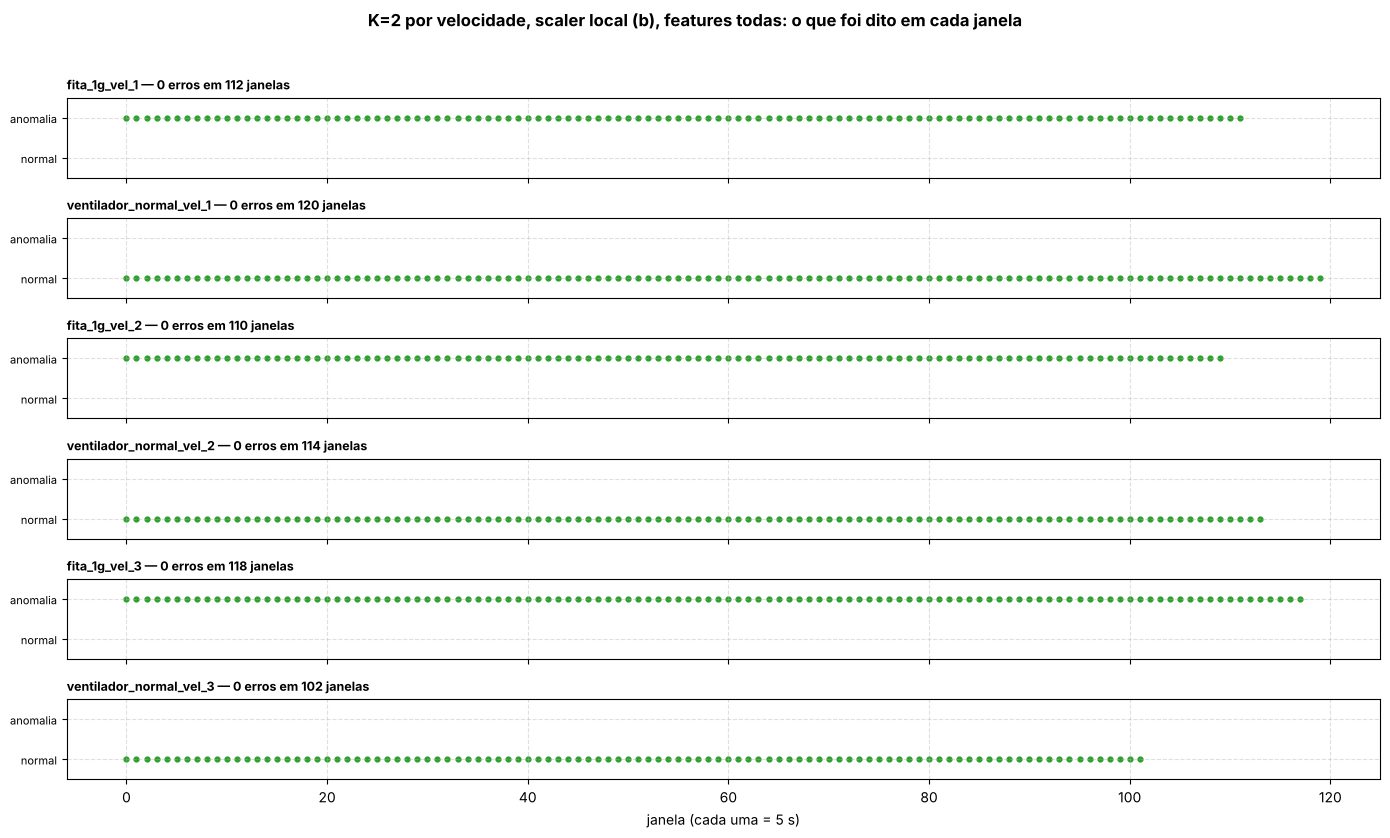

In [39]:
plotar_erros_no_tempo(resultados_k2_local_b, CONJUNTO_PRINCIPAL, gabarito)

### 12.2 — Só o Normal, em duas metades: a deriva vira "grupo"?

**O que buscamos:** pegar **só as janelas normais** de cada velocidade e pedir K=2. Se não houvesse deriva nem ciclo, os dois grupos seriam arbitrários. Comparamos os grupos com dois "rótulos de mentira":

* **metade da gravação** (primeira ou segunda metade): ARI alto = o K-Means separa **início contra fim** (deriva, por exemplo aquecimento);
* **janela par ou ímpar**: ARI alto = o K-Means separa **fase forte contra fase fraca** do ciclo (com 5 s, janelas vizinhas alternam).

**Por que importa:** se o normal sozinho já se divide em dois grupos nítidos, um K=2 com falha pode estar separando a deriva e não a falha. Nos dados antigos, a Vel 1 teve deriva de rotação de ~11 para ~13,8 Hz.

In [40]:
def testar_deriva_e_fase(features, gabarito, colunas):
    """K=2 só nas normais de cada velocidade, comparado com 'metade da gravação' e 'janela par/ímpar'."""
    linhas = []
    for velocidade in velocidades:
        sel = ((gabarito["velocidade"] == velocidade) & (gabarito["binario"] == NOME_NORMAL)).to_numpy()
        rotulos = gabarito.loc[sel]
        clusters = rodar_kmeans(padronizar_global(aplicar_log(features.loc[sel], colunas)), 2)
        posicao = rotulos.groupby("base")["janela"].rank(pct=True)
        metade = np.where(posicao > 0.5, "2ª metade", "1ª metade")
        paridade = np.where(rotulos["janela"] % 2 == 0, "par", "ímpar")
        linhas.append({"velocidade": velocidade, "janelas": int(sel.sum()),
                       "tamanho do menor grupo (%)": 100 * np.bincount(clusters).min() / len(clusters),
                       "ARI com metade da gravação": adjusted_rand_score(metade, clusters),
                       "ARI com janela par/ímpar": adjusted_rand_score(paridade, clusters)})
    return pd.DataFrame(linhas).set_index("velocidade")

In [41]:
display(testar_deriva_e_fase(features, gabarito, CONJUNTOS[CONJUNTO_PRINCIPAL]).round(3))

,janelas,tamanho do menor grupo (%),ARI com metade da gravação,ARI com janela par/ímpar
velocidade,,,,
1,120,38.333,0.584,-0.008
2,114,37.719,0.017,-0.006
3,102,46.078,-0.006,-0.006


### 12.3 — Estabilidade: o resultado muda com a semente?

**O que buscamos:** o K-Means começa de centros sorteados. Se o resultado mudar muito conforme o sorteio, ele não é confiável. Rodamos o K=2 por velocidade (scaler b) com `N_SEMENTES_ESTABILIDADE` sementes diferentes e comparamos os agrupamentos entre si pelo ARI.

* **ARI entre sementes ≈ 1:** sempre os mesmos grupos. Resultado estável.
* **ARI baixo:** os grupos mudam com o sorteio. Desconfie.

In [42]:
def testar_estabilidade(features, gabarito, colunas, n_sementes=N_SEMENTES_ESTABILIDADE):
    """ARI médio e mínimo entre os agrupamentos obtidos com sementes diferentes, por velocidade."""
    linhas = []
    for velocidade in velocidades:
        sel = (gabarito["velocidade"] == velocidade).to_numpy()
        padronizada = padronizar(aplicar_log(features.loc[sel], colunas), gabarito.loc[sel], "local_b")
        agrupamentos = [KMeans(n_clusters=2, n_init=1, random_state=s).fit_predict(padronizada.to_numpy()) for s in range(n_sementes)]
        aris = [adjusted_rand_score(agrupamentos[i], agrupamentos[j]) for i in range(n_sementes) for j in range(i + 1, n_sementes)]
        linhas.append({"velocidade": velocidade, "ARI médio entre sementes": np.mean(aris), "ARI mínimo entre sementes": np.min(aris)})
    return pd.DataFrame(linhas).set_index("velocidade")

In [43]:
display(testar_estabilidade(features, gabarito, CONJUNTOS[CONJUNTO_PRINCIPAL]).round(3))

,ARI médio entre sementes,ARI mínimo entre sementes
velocidade,,
1,1.0,1.0
2,1.0,1.0
3,1.0,1.0


### 12.4 — Janelas atípicas: o resultado depende delas?

**O que buscamos:** o Notebook 03 encontrou janelas muito fora do padrão (na fita Vel 2). O K-Means é sensível a pontos extremos, porque eles puxam os centros. Encontramos essas janelas com o mesmo critério do Notebook 03 e refazemos o K=2 por velocidade **sem elas**.

* Se o resultado não muda, ele não depende dessas janelas.
* Se melhora muito, essas janelas estavam distorcendo os grupos e vale investigar a gravação.

In [44]:
def encontrar_janelas_atipicas(features, colunas, limite_z=LIMITE_Z_ROBUSTO, min_features=MIN_FEATURES_ATIPICAS):
    """Janelas com muitas features a mais de limite_z desvios robustos (MAD) da mediana do seu grupo."""
    atipicas = pd.Series(False, index=features.index)
    for _, grupo in features.groupby(["condicao", "velocidade"]):
        valores = grupo[colunas]
        mediana = valores.median()
        desvio_robusto = 1.4826 * (valores - mediana).abs().median()
        z_robusto = (valores - mediana) / desvio_robusto.replace(0, np.nan)
        atipicas.loc[grupo.index] = (z_robusto.abs() > limite_z).sum(axis=1) >= min_features
    return atipicas

In [45]:
atipicas = encontrar_janelas_atipicas(features, COLUNAS_TODAS)
print(f"{int(atipicas.sum())} janelas atípicas:")
display(gabarito.loc[atipicas, ["base", "janela"]])

if atipicas.any():
    sem_atipicas = ~atipicas
    tabela_sem, _ = k2_por_velocidade(features.loc[sem_atipicas], gabarito.loc[sem_atipicas], "local_b",
                                      {CONJUNTO_PRINCIPAL: CONJUNTOS[CONJUNTO_PRINCIPAL]})
    com = tabela_k2_local_b[tabela_k2_local_b["features"] == CONJUNTO_PRINCIPAL].set_index("velocidade")
    sem = tabela_sem.set_index("velocidade")
    colunas_comparadas = ["acurácia (%)", f"recall {NOME_ANOMALIA} (%)", "falso alarme (%)", "ARI"]
    display(pd.concat({"com as atípicas": com[colunas_comparadas], "sem as atípicas": sem[colunas_comparadas]}, axis=1).round(2))

5 janelas atípicas:


,base,janela
112,fita_1g_vel_2,0
113,fita_1g_vel_2,1
115,fita_1g_vel_2,3
120,fita_1g_vel_2,8
221,fita_1g_vel_2,109


com as atípicas                                            \
              acurácia (%) recall anomalia (%) falso alarme (%)  ARI   
velocidade                                                             
1                    100.0               100.0              0.0  1.0   
2                    100.0               100.0              0.0  1.0   
3                    100.0               100.0              0.0  1.0   

           sem as atípicas                                            
              acurácia (%) recall anomalia (%) falso alarme (%)  ARI  
velocidade                                                            
1                    100.0               100.0              0.0  1.0  
2                    100.0               100.0              0.0  1.0  
3                    100.0               100.0              0.0  1.0

### Conclusões do Passo 12 (nesta execução)

**12.1 — Erros no tempo:** nenhum erro em nenhuma gravação no K=2 por velocidade. Não há padrão para analisar aqui, mas o gráfico fica pronto para os dados novos, em que erros alternados (ciclo) ou concentrados no início ou no fim (manuseio, aquecimento) podem aparecer.

**12.2 — Deriva e fase (só o Normal):**

| Velocidade | ARI com "metade da gravação" | ARI com "janela par/ímpar" |
| --- | --- | --- |
| 1 | **0,58** | −0,01 |
| 2 | 0,02 | −0,01 |
| 3 | −0,01 | −0,01 |

* **Vel 1:** o Normal sozinho se divide em **início × fim da gravação** (ARI 0,58). É a **deriva** já vista no Notebook 02 (rotação de ~11 para ~13,8 Hz). Mesmo assim, no Passo 9 a fita da Vel 1 ficou 100% separada. **A falha é maior que a deriva**, mas uma falha sutil na Vel 1 poderia se confundir com ela. **Regravar o Normal da Vel 1 com aquecimento** (já previsto no plano de coleta) continua importante.
* **Vel 2 e 3:** sem deriva relevante.
* **Fase do ciclo:** ARI ≈ 0 com par/ímpar em todas as velocidades. **Com as 109 features, o K-Means não separa a fase forte da fraca** do ciclo. O ciclo existe (Notebook 03), mas não é uma divisão dominante a ponto de virar grupo.

**12.3 — Estabilidade:** ARI = 1,0 entre as 10 sementes em todas as velocidades. O resultado não depende do sorteio inicial.

**12.4 — Janelas atípicas:** as mesmas 5 do Notebook 03 (fita V2: janelas 0, 1, 3, 8 e 109). Sem elas, o resultado continua 100%. **Não estão distorcendo os grupos.**

## Resumo de todos os experimentos

**O que buscamos:** uma tabela única com todos os experimentos, scalers e conjuntos de features, para comparar de relance e levar as decisões ao Notebook 05.

**Como ler:** a coluna "destaque" traz a medida mais importante de cada experimento quando a acurácia sozinha pode enganar (por exemplo, o pior recall da anomalia entre as velocidades).

In [46]:
resumo = pd.DataFrame(RESUMO).set_index(["experimento", "scaler", "features"])
display(resumo.round(2))

acurácia (%)  \
experimento                            scaler                                             features                 
K=3 só normal (velocidades)            global                                             tempo           100.00   
                                                                                          FFT             100.00   
                                                                                          rotação         100.00   
                                                                                          todas           100.00   
K=3 só anomalia (velocidades)          global                                             tempo            90.59   
                                                                                          FFT              99.41   
                                                                                          rotação          91.47   
                                                                                          todas            99.41   
K=2 global (normal x anomalia)         global                                             tempo            83.43   
                                                                                          FFT              83.43   
                                                                                          rotação          51.48   
                                                                                          todas            83.43   
K=2 por velocidade (normal x anomalia) local_b                                            tempo           100.00   
                                                                                          FFT             100.00   
                                                                                          rotação          99.85   
                                                                                          todas           100.00   
                                       local_a                                            tempo           100.00   
                                                                                          FFT             100.00   
                                                                                          rotação         100.00   
                                                                                          todas           100.00   
K=6 (velocidade x condição)            direto, scaler global                              tempo            79.44   
                                       direto, scaler local (b)                           tempo            59.91   
                                       hierárquico, K=3 em todas as janelas, scaler (b)   tempo            63.61   
                                       hierárquico, K=3 aprendido só no normal, scaler... tempo            75.44   
                                       hierárquico, velocidade do gabarito, scaler (a)... tempo           100.00   
                                       direto, scaler global                              FFT              99.70   
                                       direto, scaler local (b)                           FFT              57.69   
                                       hierárquico, K=3 em todas as janelas, scaler (b)   FFT              83.73   
                                       hierárquico, K=3 aprendido só no normal, scaler... FFT              82.69   
                                       hierárquico, velocidade do gabarito, scaler (a)... FFT             100.00   
                                       direto, scaler global                              rotação          95.27   
                                       direto, scaler local (b)                           rotação          54.14   
                                       hierárquico, K=3 em todas as janelas, scaler (b)   rotação          83.58   
                                       h

### Decisões e o que levar para o Notebook 05

**Respostas às perguntas do notebook:**

1. **As velocidades se separam sem rótulo?** Sim: 100% no normal e 99,4% na fita (todas as features), e a silhueta indica K=3 sozinha.
2. **Normal e fita se separam sem rótulo?** Sim, **dentro de cada velocidade**: 100% de recall e 0% de falso alarme. **Sem separar por velocidade, não:** a fita da Vel 1 fica 0% detectada.
3. **As 6 classes de uma vez?** Sim, com log e scaler global (99,7%). Sem log, não (57,4%).

**Decisões:**

| Decisão | Por quê |
| --- | --- |
| **Log em todas as features menos a curtose** | Sem ele, o K=6 global cai de 99,7% para 57,4%. |
| **Detector por velocidade, com scaler local (b)** | Resolve a Vel 1 (0% → 100%); o (b) imita a calibração com o ventilador saudável. |
| **Para descobrir a velocidade: regimes aprendidos só no normal** (cenário 4) | Detecção de 99,1% com 0% de falso alarme sem medir rotação. Mas **erra a velocidade da fita V3** (vai para a V2): não usar para dizer a velocidade de uma janela com falha. |
| **Descrever o "K=6 local 100%" antigo como "velocidade conhecida + K=2"** | Ele usava a velocidade do gabarito. |
| **Conjunto de features:** todas (ou FFT) | Tempo sozinho cai para ~90% ao achar a velocidade da fita e 79% no K=6. |

**Ressalvas para levar ao orientador (e ao texto do TCC):**

* **Uma falha só, e forte.** A fita separa em 100% em quase tudo. Isso mostra que ela é detectável, não que o método pega falhas sutis.
* **Uma gravação por classe.** Separar classes também é separar sessões de gravação. A nova coleta, com rodadas de Normal intercaladas, mostra quanto disso é efeito de sessão.
* **Deriva na Vel 1:** o Normal da Vel 1 se divide sozinho em início e fim da gravação.
* **Sem treino/teste aqui:** os scalers foram ajustados nos próprios dados. No Notebook 05 eles serão ajustados só no treino, com validação por blocos de tempo.

**Para o Notebook 05 (classificação):** testar a arquitetura em duas etapas (velocidade, depois detector), com validação por blocos e teste trancado, e conferir se a fita V3 continua sendo confundida com o regime da Vel 2 quando a velocidade é aprendida **com** rótulos.

## O que conferir antes de seguir para o Notebook 05

* [ ] **Passos 3 e 4:** você entendeu por que o log e o scaler local, e a diferença entre os scalers (a) e (b).
* [ ] **Passo 5:** você sabe ler a matriz de confusão e diferenciar acurácia, recall, precisão e ARI.
* [ ] **Passos 6 e 7:** as velocidades são descobertas sem rótulo?
* [ ] **Passo 8:** o K=2 global falhou em alguma velocidade? Por quê?
* [ ] **Passo 9:** recall da anomalia e falso alarme por velocidade, com o scaler (b), estão anotados.
* [ ] **Passo 10:** a diferença entre o K=6 com velocidade descoberta e com velocidade do gabarito está clara.
* [ ] **Passo 12:** os erros no tempo, a deriva e a fase foram verificados.

**Próximo passo:** Notebook 05, **classificação com rótulos**, com validação por blocos de tempo e scalers ajustados **só no treino**.